# Smart Waste Classification System — MobileNetV2 Transfer Learning

This notebook trains the computer vision model used by the **Smart Waste** web application.
It classifies a photo of a waste item into one of six categories:

**cardboard · glass · metal · paper · plastic · trash**

| Stage | What happens |
|---|---|
| 1. Environment | Libraries, versions, GPU check, reproducible seed |
| 2. Dataset | Download **TrashNet** (studio photos), **RealWaste** (landfill photos) and the **Garbage Dataset** (web photos) and organise them into `dataset/<class>/` |
| 3. Analysis | Image counts, class distribution, sample images, image sizes |
| 4. Cleaning | Detect corrupted, unreadable, unsupported, duplicate and near-duplicate files |
| 5. Split | Stratified train / validation / test split with a fixed seed |
| 6. Preprocessing | 224 × 224 RGB, MobileNetV2 normalisation embedded in the model |
| 7. Augmentation | Flips, small rotations, zoom, translation, contrast and brightness — training only |
| 8. Class weights | Computed from the training split when the classes are imbalanced |
| 9–10. Transfer learning | Frozen MobileNetV2 base + new classification head |
| 11. Curves | Accuracy and loss for training and validation |
| 12. Fine-tuning | Unfreeze the deepest MobileNetV2 blocks, train with a small learning rate |
| 13–15. Evaluation | Untouched test set: accuracy, loss, precision, recall, F1, confusion matrix |
| 16–17. Testing | `predict_image()` and random test predictions |
| 18. Save | `smart_waste_mobilenetv2.keras` |
| 19–21. Web export | Convert to ONNX, verify against Keras, write `metadata.json` for the web app |

**How to run:** in Google Colab choose *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*.
Every cell depends only on the cells above it, so the notebook runs top to bottom without edits.
It also runs locally in Jupyter (see `training/requirements.txt`), just more slowly without a GPU.

> **No result in this notebook is pre-filled.** Every number you see is produced when you run it.

## Section 1 — Environment setup

We import the libraries, fix the random seed so the split and training are reproducible, and check for a GPU.

In [1]:
import datetime
import hashlib
import json
import os
import platform
import random
import shutil
import sys
import time
import urllib.parse
import urllib.request
import zipfile
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from PIL import Image, UnidentifiedImageError
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
import keras
from keras import layers

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
keras.utils.set_random_seed(SEED)

IN_COLAB = "google.colab" in sys.modules
WORK_DIR = Path("/content") if IN_COLAB else Path.cwd()
RAW_DIR = WORK_DIR / "trashnet_raw"
DATA_DIR = WORK_DIR / "dataset"
REJECTED_DIR = WORK_DIR / "dataset_rejected"
ARTIFACTS_DIR = WORK_DIR / "artifacts"
CHECKPOINT_DIR = ARTIFACTS_DIR / "checkpoints"
WEB_MODEL_DIR = ARTIFACTS_DIR / "web_model"
for directory in (ARTIFACTS_DIR, CHECKPOINT_DIR, WEB_MODEL_DIR):
    directory.mkdir(parents=True, exist_ok=True)

EXPECTED_CLASSES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
ALLOWED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

print(f"Python        : {sys.version.split()[0]} on {platform.system()} {platform.machine()}")
print(f"TensorFlow    : {tf.__version__}")
print(f"Keras         : {keras.__version__}")
print(f"NumPy         : {np.__version__}")
print(f"scikit-learn  : {sklearn.__version__}")
print(f"Matplotlib    : {matplotlib.__version__}")
print(f"Running in    : {'Google Colab' if IN_COLAB else 'local Jupyter'}")
print(f"Working dir   : {WORK_DIR}")

gpus = tf.config.list_physical_devices("GPU")
if gpus:
    for gpu in gpus:
        print(f"GPU available : {gpu.name}")
else:
    print("GPU available : none — training will run on the CPU and be much slower.")
    if IN_COLAB:
        print("                In Colab use Runtime → Change runtime type → T4 GPU, then rerun.")

Python        : 3.12.10 on Windows AMD64
TensorFlow    : 2.20.0
Keras         : 3.15.1
NumPy         : 2.5.3
scikit-learn  : 1.9.1
Matplotlib    : 3.11.2
Running in    : local Jupyter
Working dir   : C:\Users\User\computer_vision\smart-waste\training
GPU available : none — training will run on the CPU and be much slower.


In [2]:
INK, INK_MUTED, GRID = "#1c1f1d", "#565c58", "#e6e8e3"
COLORS = {
    "train": "#2a78d6",
    "validation": "#eb6834",
    "third": "#1baf7a",
    "brand": "#1f7f40",
    "correct": "#1f7f40",
    "wrong": "#c62828",
}
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#d3d7d0",
    "axes.labelcolor": INK,
    "axes.titlecolor": INK,
    "axes.titleweight": "bold",
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "legend.frameon": False,
})

## Section 2 — Dataset

This project combines **three real, public datasets** so the model sees clean studio photos, messy real-world waste
and the kind of everyday web photos people upload to the app.

### TrashNet (studio photos)

**TrashNet** by Gary Thung and Mindy Yang, created for the Stanford CS229 project
*"Classification of Trash for Recyclability Status"* (2016).

* Source: <https://github.com/garythung/trashnet> (mirror: <https://huggingface.co/datasets/garythung/trashnet>)
* Exactly our six classes: **cardboard, glass, metal, paper, plastic, trash**.
* Each photo shows a single object on a plain white background. We use the authors' `dataset-resized.zip` (~43 MB).

### RealWaste (real-world photos)

**RealWaste** by Sam Single, Saeid Iranmanesh and Raad Raad (University of Wollongong), published in the
UCI Machine Learning Repository under **CC BY 4.0**: <https://archive.ics.uci.edu/dataset/908/realwaste>.

* 4,752 photos of real waste collected at a landfill, with varied lighting, dirt, damage and backgrounds.
* We download it from a Hugging Face mirror of the same files (pinned to one exact version, downloaded with retries,
  and every class count is checked against the official totals): <https://huggingface.co/datasets/shahzaibvohra/realwaste>.
* Class mapping to our six categories:

| RealWaste class | Smart Waste class |
|---|---|
| Cardboard | cardboard |
| Glass | glass |
| Metal | metal |
| Paper | paper |
| Plastic | plastic |
| Miscellaneous Trash | trash |
| Food Organics, Vegetation, Textile Trash | *not used* — compostable/textile waste is not one of our six categories, and adding it to *trash* would distort that class |

### Garbage Dataset (web photos)

**Garbage Dataset** by Suman Kunwar, released under the **MIT licence** (10 classes, 19,762 images collected from
the web and from phone photos). We download it from a Hugging Face mirror pinned to one exact version:
<https://huggingface.co/datasets/steveharianto/waste-garbage-management-dataset>.

* Its *cardboard, glass, metal, paper, plastic* and *trash* folders map one-to-one to our classes. *Biological,
  battery, shoes* and *clothes* are not used, for the same reason as RealWaste's organic and textile classes.
* The Garbage Dataset already contains most of TrashNet. Those copies are detected with a perceptual hash and
  skipped first, so only genuinely new photos are considered.
* Of the new photos, at most **1,000 per class** are taken (a seeded random sample, so the selection is identical on
  every run).
  The cap keeps the three sources roughly balanced within each class; otherwise one class would be dominated by web
  photos and another by landfill photos, and the model could learn the photo style instead of the material.

**Why three datasets:** a model trained only on TrashNet learns "single object on a white board". Photos that look
different (cluttered backgrounds, piles of material, outdoor light) can then be misclassified with high confidence.
RealWaste adds cluttered real-world scenes, and the Garbage Dataset adds varied web and phone photos
(stock-style product shots, piles of cans and scrap, different lighting and backgrounds).

**Known limitations:**

* Several photos may show the same physical object from different angles; such near-duplicates can make
  test scores slightly optimistic. Exact duplicates are removed in Section 4.
* Web photos can be near-duplicates of each other or of TrashNet images; Section 4 removes images that are
  visually identical (same perceptual hash) so they cannot leak between the training and test sets.
* No dataset covers every kind of waste photo. Unusual scenes (for example industrial stock such as pipes and
  beams) may still be classified with low confidence; the app flags those results as uncertain.

Each file is copied into the class folders with a prefix that records its source (`trashnet_…`, `realwaste_…` or `garbage_…`):

```
dataset/
├── cardboard/
├── glass/
├── metal/
├── paper/
├── plastic/
└── trash/
```

If `dataset/` is already prepared with both sources, the downloads are skipped.

In [3]:
TRASHNET_URLS = [
    "https://github.com/garythung/trashnet/raw/master/data/dataset-resized.zip",
    "https://huggingface.co/datasets/garythung/trashnet/resolve/main/dataset-resized.zip",
]
TRASHNET_ZIP_BYTES = 42_834_870
TRASHNET_ZIP = WORK_DIR / "trashnet-dataset-resized.zip"

REALWASTE_REPO = "shahzaibvohra/realwaste"
REALWASTE_REVISION = "c626504f80c98ffe0d437e8ebf65a642e8d9fdba"
REALWASTE_DIR = WORK_DIR / "realwaste_raw"
REALWASTE_CLASS_MAP = {
    "Cardboard": "cardboard",
    "Glass": "glass",
    "Metal": "metal",
    "Paper": "paper",
    "Plastic": "plastic",
    "Miscellaneous Trash": "trash",
}
REALWASTE_EXPECTED_COUNTS = {
    "Cardboard": 461,
    "Glass": 420,
    "Metal": 790,
    "Paper": 500,
    "Plastic": 921,
    "Miscellaneous Trash": 495,
}
GARBAGE_REPO = "steveharianto/waste-garbage-management-dataset"
GARBAGE_REVISION = "30af9027084bc44f66011e7e37bf852392d2f34d"
GARBAGE_DIR = WORK_DIR / "garbage_raw"
GARBAGE_EXPECTED_COUNTS = {
    "cardboard": 1825,
    "glass": 3061,
    "metal": 1020,
    "paper": 1680,
    "plastic": 1984,
    "trash": 947,
}
GARBAGE_MAX_PER_CLASS = 1000

CUSTOM_DIR = WORK_DIR / "custom_real"
# custom_real/<class>/ holds extra real photos; the folder name is the class label

SOURCES = ["trashnet", "realwaste", "garbage", "custom"]
SOURCES_MARKER = DATA_DIR / "SOURCES.json"
MARKER_VALUE = SOURCES + [CUSTOM_DIR.name]


def download_trashnet():
    if TRASHNET_ZIP.exists() and TRASHNET_ZIP.stat().st_size == TRASHNET_ZIP_BYTES:
        print(f"TrashNet archive already present: {TRASHNET_ZIP}")
        return
    errors = []
    for url in TRASHNET_URLS:
        try:
            print(f"Downloading {url} ...")
            urllib.request.urlretrieve(url, TRASHNET_ZIP)
        except Exception as exc:
            errors.append(f"{url}: {exc}")
            continue
        size = TRASHNET_ZIP.stat().st_size
        if size == TRASHNET_ZIP_BYTES:
            print(f"Downloaded {size / 1e6:.1f} MB")
            return
        errors.append(f"{url}: expected {TRASHNET_ZIP_BYTES} bytes but received {size}")
    raise RuntimeError(
        "TrashNet could not be downloaded from any source:\n  " + "\n  ".join(errors)
        + "\nDownload dataset-resized.zip manually from https://github.com/garythung/trashnet "
        + f"and place it at {TRASHNET_ZIP}."
    )


def fetch_hf_file(repo, revision, name, target_dir):
    target = target_dir / name
    if target.exists() and target.stat().st_size > 0:
        return
    target.parent.mkdir(parents=True, exist_ok=True)
    url = f"https://huggingface.co/datasets/{repo}/resolve/{revision}/{urllib.parse.quote(name)}"
    last_error = None
    for attempt in range(5):
        try:
            with urllib.request.urlopen(url, timeout=30) as response:
                data = response.read()
            partial = target.with_name(target.name + ".part")
            partial.write_bytes(data)
            partial.replace(target)
            return
        except Exception as exc:
            last_error = exc
            time.sleep(2 * (attempt + 1))
    raise RuntimeError(f"Could not download {name}: {last_error}")


def list_hf_files(repo, revision):
    listing_url = f"https://huggingface.co/api/datasets/{repo}/revision/{revision}"
    with urllib.request.urlopen(listing_url, timeout=60) as response:
        return [entry["rfilename"] for entry in json.load(response)["siblings"]]


def download_realwaste():
    all_files = list_hf_files(REALWASTE_REPO, REALWASTE_REVISION)
    wanted = [name for name in all_files if name.endswith(".jpg") and name.rsplit("_", 1)[0] in REALWASTE_CLASS_MAP]
    REALWASTE_DIR.mkdir(parents=True, exist_ok=True)
    print(f"Downloading {len(wanted)} RealWaste images from {REALWASTE_REPO} @ {REALWASTE_REVISION[:7]} ...")
    with ThreadPoolExecutor(max_workers=8) as pool:
        fetch = lambda name: fetch_hf_file(REALWASTE_REPO, REALWASTE_REVISION, name, REALWASTE_DIR)
        for done, _ in enumerate(pool.map(fetch, wanted), start=1):
            if done % 500 == 0 or done == len(wanted):
                print(f"  {done}/{len(wanted)} files ready")
    counts = {name: len(list(REALWASTE_DIR.glob(f"{name}_*.jpg"))) for name in REALWASTE_CLASS_MAP}
    if counts != REALWASTE_EXPECTED_COUNTS:
        raise RuntimeError(f"RealWaste download is incomplete or changed: {counts} != {REALWASTE_EXPECTED_COUNTS}")
    print(f"RealWaste verified: {sum(counts.values())} images in the six mapped classes")


def difference_hash(path, hash_size=8):
    with Image.open(path) as img:
        pixels = np.asarray(img.convert("L").resize((hash_size + 1, hash_size), Image.Resampling.LANCZOS), dtype=np.int16)
    bits = (pixels[:, 1:] > pixels[:, :-1]).flatten()
    return int("".join("1" if bit else "0" for bit in bits), 2)


def safe_difference_hash(path):
    try:
        return difference_hash(path)
    except (UnidentifiedImageError, OSError, ValueError):
        return None


def download_garbage():
    all_files = list_hf_files(GARBAGE_REPO, GARBAGE_REVISION)
    available = {}
    for name in EXPECTED_CLASSES:
        pool = sorted(f for f in all_files if f.startswith(f"{name}/") and Path(f).suffix.lower() in ALLOWED_EXTENSIONS)
        if len(pool) != GARBAGE_EXPECTED_COUNTS[name]:
            raise RuntimeError(f"Garbage Dataset changed: {name} has {len(pool)} images, expected {GARBAGE_EXPECTED_COUNTS[name]}")
        available[name] = pool
    wanted = [name for names in available.values() for name in names]
    print(f"Downloading {len(wanted)} Garbage Dataset images from {GARBAGE_REPO} @ {GARBAGE_REVISION[:7]} ...")
    with ThreadPoolExecutor(max_workers=8) as pool:
        fetch = lambda name: fetch_hf_file(GARBAGE_REPO, GARBAGE_REVISION, name, GARBAGE_DIR)
        for done, _ in enumerate(pool.map(fetch, wanted), start=1):
            if done % 1000 == 0 or done == len(wanted):
                print(f"  {done}/{len(wanted)} files ready")
    return available


def select_garbage_files(available, trashnet_root):
    trashnet_hashes = {
        safe_difference_hash(path) for path in trashnet_root.rglob("*") if path.suffix.lower() in ALLOWED_EXTENSIONS
    }
    trashnet_hashes.discard(None)
    rng = random.Random(SEED)
    selected = {}
    print("Garbage Dataset selection:")
    for name, files in available.items():
        new = [f for f in files if safe_difference_hash(GARBAGE_DIR / f) not in trashnet_hashes]
        selected[name] = sorted(rng.sample(new, min(GARBAGE_MAX_PER_CLASS, len(new))))
        print(f"  {name:<9} {len(files):>5} images, {len(files) - len(new):>4} TrashNet copies skipped, {len(selected[name]):>5} used")
    return selected


def find_class_root(root):
    candidates = [root, *sorted(p for p in root.rglob("*") if p.is_dir() and "__MACOSX" not in p.parts)]
    for candidate in candidates:
        child_names = {child.name.lower() for child in candidate.iterdir() if child.is_dir()}
        if set(EXPECTED_CLASSES) <= child_names:
            return candidate
    raise FileNotFoundError(f"No folder inside {root} contains all of: {EXPECTED_CLASSES}")


def dataset_ready():
    return SOURCES_MARKER.exists() and json.loads(SOURCES_MARKER.read_text()) == MARKER_VALUE


def prepare_dataset():
    if dataset_ready():
        print(f"dataset/ is already prepared at {DATA_DIR} with sources {SOURCES} — skipping downloads.")
        return
    download_trashnet()
    download_realwaste()
    garbage_available = download_garbage()

    if RAW_DIR.exists():
        shutil.rmtree(RAW_DIR)
    with zipfile.ZipFile(TRASHNET_ZIP) as archive:
        archive.extractall(RAW_DIR)
    class_root = find_class_root(RAW_DIR)
    garbage_files = select_garbage_files(garbage_available, class_root)

    if DATA_DIR.exists():
        shutil.rmtree(DATA_DIR)
    for name in EXPECTED_CLASSES:
        (DATA_DIR / name).mkdir(parents=True)
        source_dir = next(child for child in class_root.iterdir() if child.is_dir() and child.name.lower() == name)
        for path in sorted(source_dir.iterdir()):
            if path.is_file():
                shutil.copy2(path, DATA_DIR / name / f"trashnet_{path.name}")
    for realwaste_name, name in REALWASTE_CLASS_MAP.items():
        for path in sorted(REALWASTE_DIR.glob(f"{realwaste_name}_*.jpg")):
            shutil.copy2(path, DATA_DIR / name / f"realwaste_{path.name.replace(' ', '_')}")
    for name, files in garbage_files.items():
        for file_name in files:
            path = GARBAGE_DIR / file_name
            shutil.copy2(path, DATA_DIR / name / f"garbage_{path.name.replace(' ', '_')}")
    if CUSTOM_DIR.exists():
        for path in sorted(CUSTOM_DIR.rglob("*")):
            if path.is_file() and path.suffix.lower() in ALLOWED_EXTENSIONS and path.parent.name in EXPECTED_CLASSES:
                shutil.copy2(path, DATA_DIR / path.parent.name / f"custom_{path.name.replace(' ', '_')}")
    SOURCES_MARKER.write_text(json.dumps(MARKER_VALUE))
    print(f"Dataset organised into {DATA_DIR}")


def source_of(path):
    return Path(path).name.split("_", 1)[0]


prepare_dataset()

TrashNet archive already present: C:\Users\User\computer_vision\smart-waste\training\trashnet-dataset-resized.zip


  500/3587 files ready
  1000/3587 files ready
  1500/3587 files ready


  2000/3587 files ready
  2500/3587 files ready
  3000/3587 files ready
  3500/3587 files ready
  3587/3587 files ready


RealWaste verified: 3587 images in the six mapped classes


  1000/10517 files ready
  2000/10517 files ready


...

  metal      1020 images,  410 TrashNet copies skipped,   610 used


  paper      1680 images,  594 TrashNet copies skipped,  1000 used


  plastic    1984 images,  482 TrashNet copies skipped,  1000 used


  trash       947 images,  136 TrashNet copies skipped,   811 used


Dataset organised into C:\Users\User\computer_vision\smart-waste\training\dataset


### Verify the dataset and display the six classes

We confirm that every expected class folder exists, report any unexpected folders, and count the files per class
and per source. Files with extensions other than JPG/JPEG/PNG/WEBP are counted separately and handled in Section 4.

In [4]:
found_classes = sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir())
missing_classes = sorted(set(EXPECTED_CLASSES) - set(found_classes))
unexpected_classes = sorted(set(found_classes) - set(EXPECTED_CLASSES))

print("Class folders found:", found_classes)
if missing_classes:
    raise RuntimeError(f"Missing class folders: {missing_classes}")
if unexpected_classes:
    print(f"WARNING: unexpected folders will be ignored: {unexpected_classes}")

rows = []
for name in EXPECTED_CLASSES:
    for path in (DATA_DIR / name).iterdir():
        if path.is_file():
            rows.append({"class": name, "source": source_of(path), "is_image": path.suffix.lower() in ALLOWED_EXTENSIONS})
inventory = pd.DataFrame(rows)

file_counts = (
    inventory[inventory["is_image"]].pivot_table(index="class", columns="source", aggfunc="size", fill_value=0)
    .reindex(index=EXPECTED_CLASSES, columns=SOURCES, fill_value=0)
)
file_counts["total"] = file_counts.sum(axis=1)
print(f"\nThe six classes: {', '.join(EXPECTED_CLASSES)}\n")
print(file_counts.to_string())
print(f"\nTotal image files: {file_counts['total'].sum()}")
other_files = int((~inventory["is_image"]).sum())
if other_files:
    print(f"Non-image files found: {other_files} (removed during cleaning)")

Class folders found: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']



The six classes: cardboard, glass, metal, paper, plastic, trash

source     trashnet  realwaste  garbage  custom  total
class                                                 
cardboard       403        461     1000       0   1864
glass           501        420     1000      28   1949
metal           410        790      610      47   1857
paper           594        500     1000       0   2094
plastic         482        921     1000       0   2403
trash           137        495      811      26   1469

Total image files: 11636


## Section 3 — Dataset analysis

Before training we look at the data: how many images each class has per source, whether the classes are balanced,
what the images look like, and what sizes they are.

Total images: 11636

source     trashnet  realwaste  garbage  custom  total  share_%
class                                                          
cardboard       403        461     1000       0   1864    16.02
glass           501        420     1000      28   1949    16.75
metal           410        790      610      47   1857    15.96
paper           594        500     1000       0   2094    18.00
plastic         482        921     1000       0   2403    20.65
trash           137        495      811      26   1469    12.62

Largest class : plastic (2403 images)
Smallest class: trash (1469 images)
Imbalance ratio (largest / smallest): 1.64
→ The dataset is imbalanced. Class weights will be computed in Section 8.


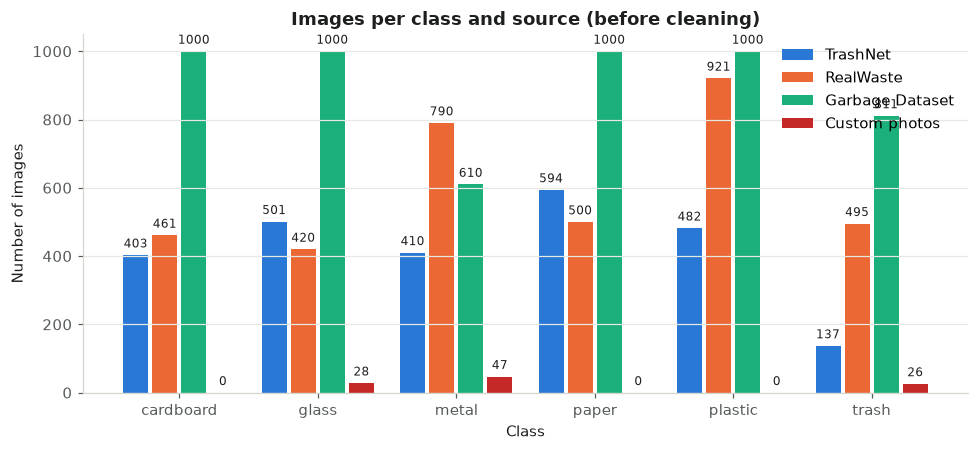

In [5]:
counts = file_counts["total"]
total_images = int(counts.sum())
distribution = file_counts.assign(**{"share_%": (counts / total_images * 100).round(2)})
print(f"Total images: {total_images}\n")
print(distribution.to_string())

imbalance_ratio = counts.max() / counts.min()
print(f"\nLargest class : {counts.idxmax()} ({counts.max()} images)")
print(f"Smallest class: {counts.idxmin()} ({counts.min()} images)")
print(f"Imbalance ratio (largest / smallest): {imbalance_ratio:.2f}")
if imbalance_ratio > 1.5:
    print("→ The dataset is imbalanced. Class weights will be computed in Section 8.")
else:
    print("→ The classes are reasonably balanced.")

fig, ax = plt.subplots(figsize=(9, 4.2))
positions = np.arange(len(EXPECTED_CLASSES))
width = 0.21
for offset, source, color, label in ((-width, "trashnet", COLORS["train"], "TrashNet"), (0, "realwaste", COLORS["validation"], "RealWaste"), (width, "garbage", COLORS["third"], "Garbage Dataset"), (2 * width, "custom", COLORS["wrong"], "Custom photos")):
    bars = ax.bar(positions + offset - width / 2, file_counts[source], width=width - 0.03, color=color, label=label)
    ax.bar_label(bars, padding=3, color=INK, fontsize=8)
ax.set_xticks(positions, labels=EXPECTED_CLASSES)
ax.set_title("Images per class and source (before cleaning)")
ax.set_xlabel("Class")
ax.set_ylabel("Number of images")
ax.grid(axis="x", visible=False)
ax.legend()
plt.tight_layout()
plt.show()

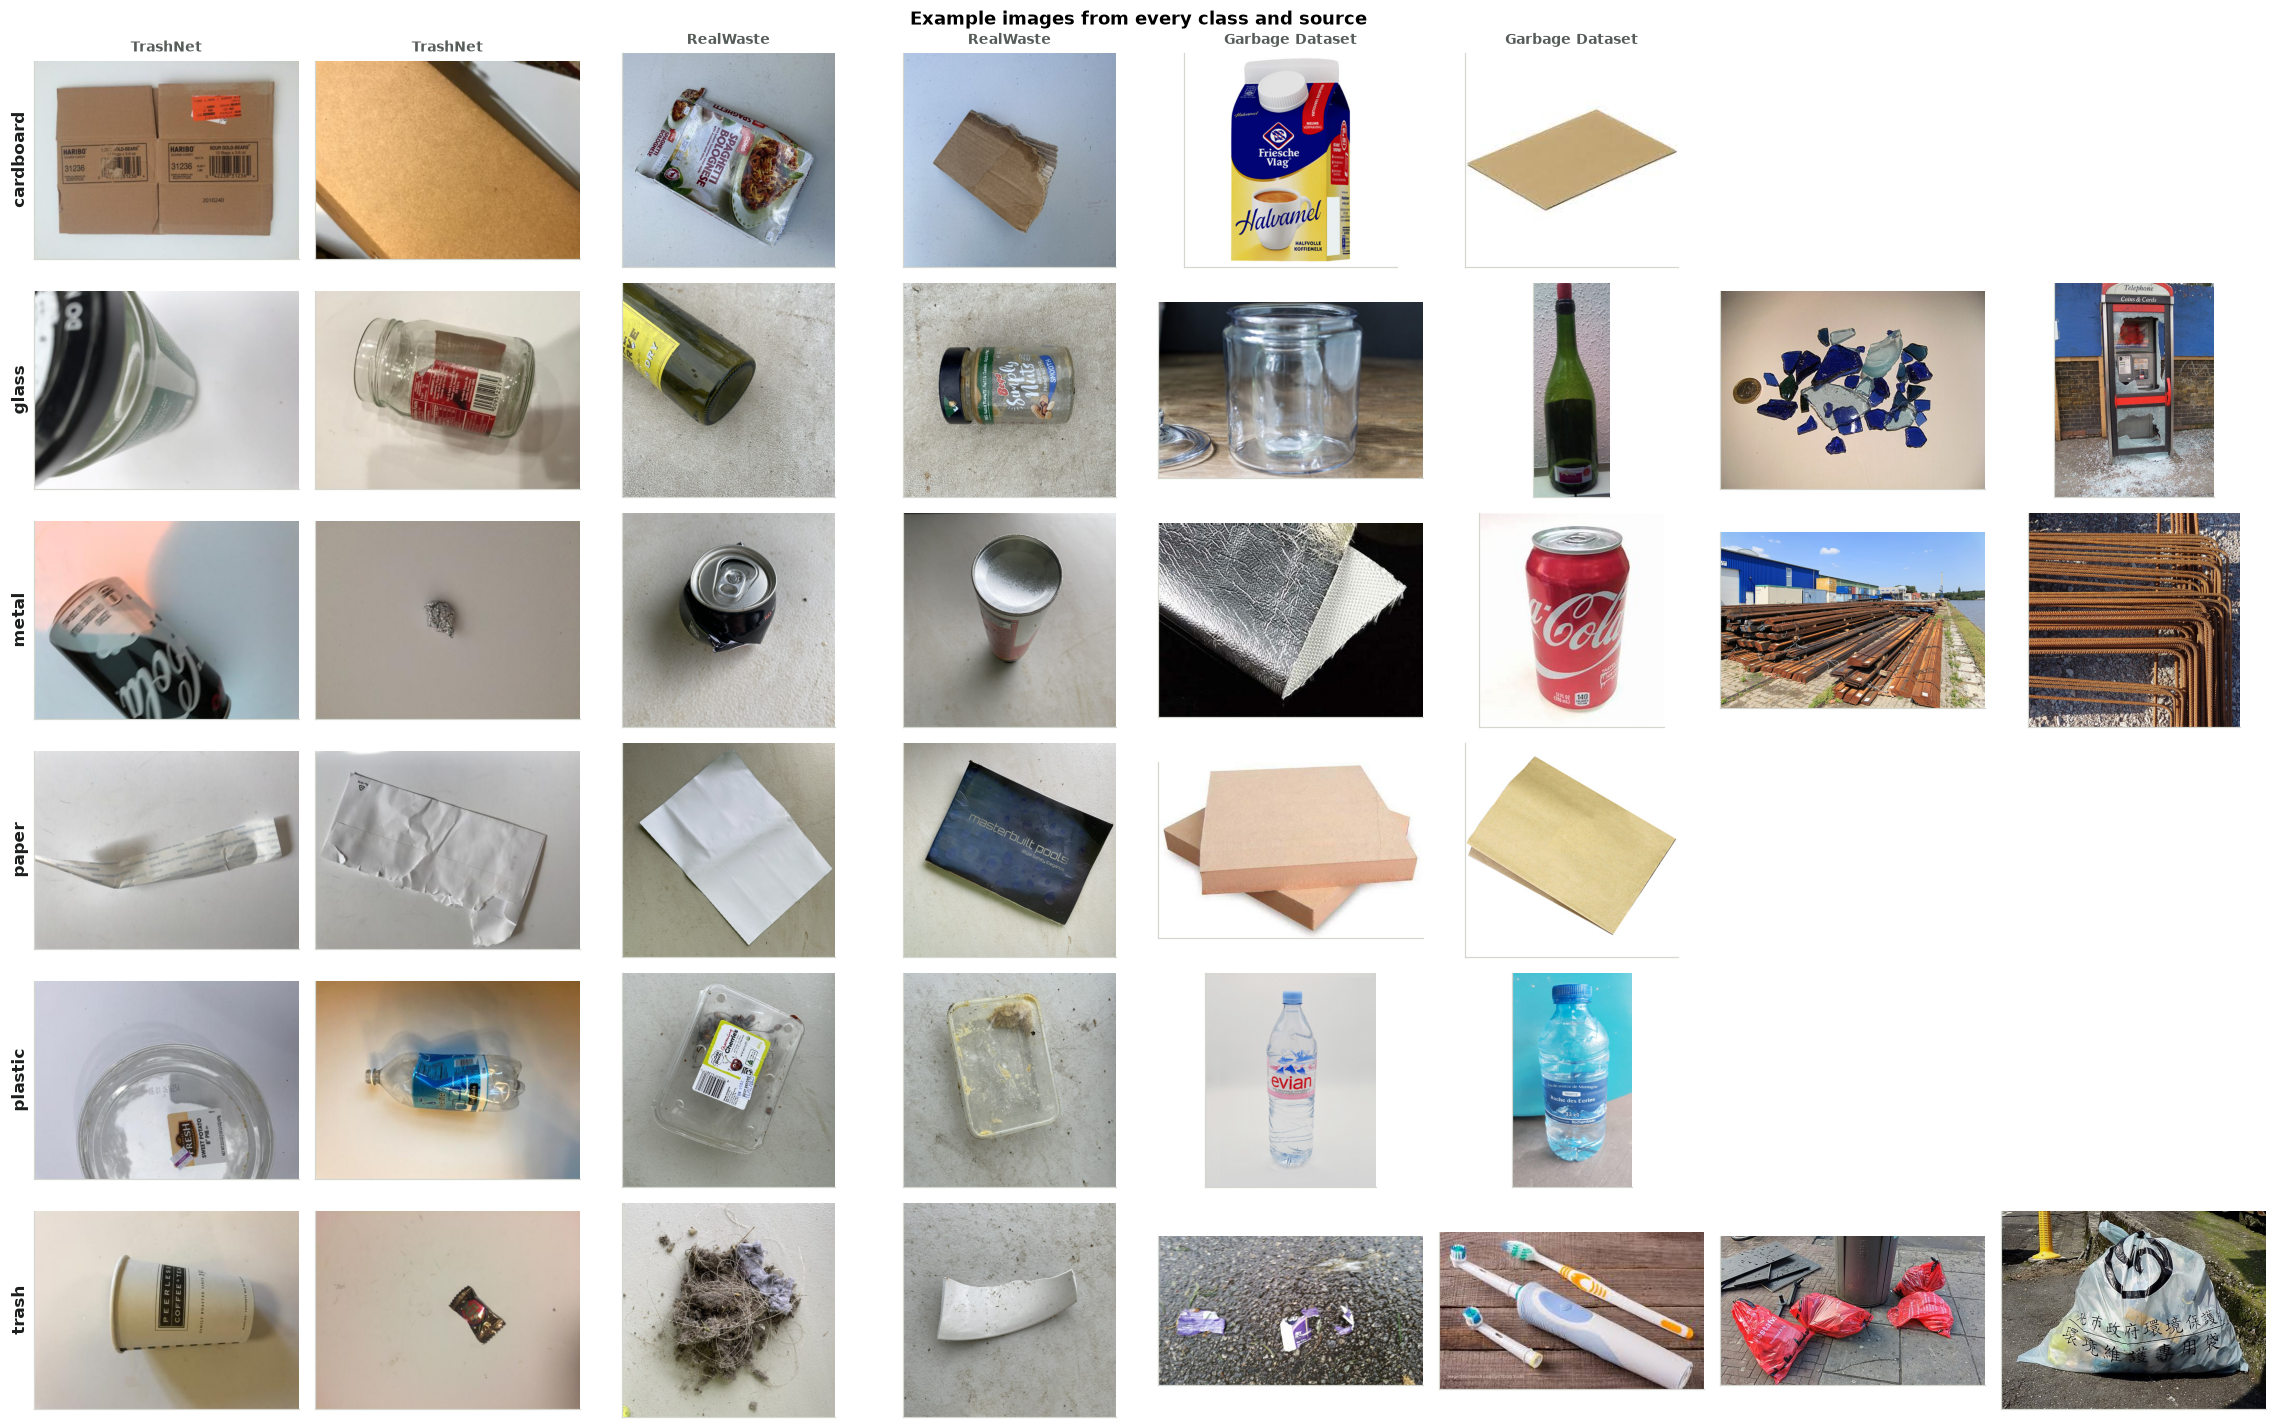

In [6]:
SAMPLES_PER_SOURCE = 2
rng = np.random.default_rng(SEED)
columns = SAMPLES_PER_SOURCE * len(SOURCES)
TITLES = {"trashnet": "TrashNet", "realwaste": "RealWaste", "garbage": "Garbage Dataset", "custom": "Custom photos"}

fig, axes = plt.subplots(len(EXPECTED_CLASSES), columns, figsize=(columns * 2.6, len(EXPECTED_CLASSES) * 2.2))
for row, name in enumerate(EXPECTED_CLASSES):
    images = sorted(p for p in (DATA_DIR / name).iterdir() if p.suffix.lower() in ALLOWED_EXTENSIONS)
    chosen = []
    for source in SOURCES:
        pool = [p for p in images if source_of(p) == source]
        if pool:
            chosen += [(source, p) for p in rng.choice(pool, size=SAMPLES_PER_SOURCE, replace=False)]
    for ax in axes[row, len(chosen):]:
        ax.axis("off")
    for col, (source, path) in enumerate(chosen):
        ax = axes[row, col]
        with Image.open(path) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        if row == 0:
            ax.set_title(TITLES[source], fontsize=9, color=INK_MUTED)
        if col == 0:
            ax.set_ylabel(name, fontsize=11, fontweight="bold", color=INK)
fig.suptitle("Example images from every class and source", fontweight="bold")
plt.tight_layout()
plt.show()

In [7]:
size_counter = Counter()
mode_counter = Counter()
for name in EXPECTED_CLASSES:
    for path in (DATA_DIR / name).iterdir():
        if path.suffix.lower() not in ALLOWED_EXTENSIONS:
            continue
        try:
            with Image.open(path) as img:
                size_counter[(source_of(path), img.size)] += 1
                mode_counter[img.mode] += 1
        except (UnidentifiedImageError, OSError):
            size_counter[(source_of(path), "unreadable")] += 1

print("Most common image sizes (source, width × height):")
for (source, size), n in size_counter.most_common(6):
    label = size if isinstance(size, str) else f"{size[0]} × {size[1]}"
    print(f"  {source:<9} {label}: {n} images")
print("\nColour modes:", dict(mode_counter))
print(f"\nAll images will be resized to {IMG_SIZE[0]} × {IMG_SIZE[1]} RGB for MobileNetV2.")

Most common image sizes (source, width × height):
  realwaste 524 × 524: 3587 images
  trashnet  512 × 384: 2527 images
  garbage   225 × 225: 752 images
  garbage   474 × 474: 173 images
  garbage   275 × 183: 164 images
  garbage   800 × 450: 146 images

Colour modes: {'RGB': 11421, 'RGBA': 200, 'L': 2, 'P': 13}

All images will be resized to 224 × 224 RGB for MobileNetV2.


## Section 4 — Dataset cleaning

Each file is checked for:

* an unsupported extension (e.g. hidden system files such as `.DS_Store`),
* an empty file,
* an image that Pillow cannot fully decode (corrupted or truncated),
* an image that TensorFlow cannot decode (TensorFlow is what reads images during training),
* an **exact duplicate** of another image (same bytes), or a **near-duplicate**: the same picture re-saved, resized
  or re-compressed, detected with the same 64-bit perceptual difference hash (dHash) used in Section 2. Web datasets often
  contain such copies. Duplicates are removed because a copy in the training set and a copy in the
  test set would leak information and inflate the test score.

Problem files are **moved** (not deleted) to `dataset_rejected/` so you can inspect them, and every problem is listed.
If more than 5% of the files are rejected **for being broken** (not for being duplicates) the notebook stops, because
that indicates a real dataset problem.

In [8]:
def inspect_image(path):
    if path.suffix.lower() not in ALLOWED_EXTENSIONS:
        return "unsupported file type"
    if path.stat().st_size == 0:
        return "empty file"
    try:
        with Image.open(path) as img:
            img.verify()
        with Image.open(path) as img:
            img.convert("RGB").load()
    except (UnidentifiedImageError, OSError, SyntaxError, ValueError) as exc:
        return f"unreadable by Pillow ({type(exc).__name__})"
    try:
        tf.io.decode_image(tf.io.read_file(str(path)), channels=3, expand_animations=False)
    except (tf.errors.InvalidArgumentError, tf.errors.UnknownError):
        return "unreadable by TensorFlow"
    return None


def file_md5(path):
    return hashlib.md5(path.read_bytes()).hexdigest()


valid_records, rejected = [], []
seen_hashes = {}
seen_dhashes = {}
for name in EXPECTED_CLASSES:
    for path in sorted((DATA_DIR / name).iterdir()):
        if not path.is_file():
            continue
        problem = inspect_image(path)
        digest = None
        if problem is None:
            digest = file_md5(path)
            dhash = difference_hash(path)
            if digest in seen_hashes:
                problem = f"exact duplicate of {seen_hashes[digest]}"
            elif dhash in seen_dhashes:
                problem = f"near-duplicate of {seen_dhashes[dhash]}"
            else:
                seen_hashes[digest] = f"{name}/{path.name}"
                seen_dhashes[dhash] = f"{name}/{path.name}"
        if problem:
            rejected.append({"file": f"{name}/{path.name}", "problem": problem})
        else:
            valid_records.append({"path": str(path), "label": name, "md5": digest})

total_files = len(valid_records) + len(rejected)
print(f"Files checked : {total_files}")
print(f"Valid images  : {len(valid_records)}")
print(f"Rejected      : {len(rejected)}")

if rejected:
    rejected_df = pd.DataFrame(rejected)
    print("\nRejected files by reason:")
    print(rejected_df["problem"].str.replace(r" of .*$", "", regex=True).value_counts().to_string())
    print("\nFirst 25 rejected files:")
    print(rejected_df.head(25).to_string(index=False))
    for item in rejected:
        source = DATA_DIR / item["file"]
        target = REJECTED_DIR / item["file"]
        target.parent.mkdir(parents=True, exist_ok=True)
        shutil.move(str(source), str(target))
    print(f"\nMoved rejected files to {REJECTED_DIR}")

broken = [item for item in rejected if "duplicate" not in item["problem"]]
rejected_share = len(broken) / max(total_files, 1)
if rejected_share > 0.05:
    raise RuntimeError(
        f"{rejected_share:.1%} of files are broken — inspect {REJECTED_DIR} before training."
    )

Files checked : 11636
Valid images  : 11314
Rejected      : 322

Rejected files by reason:
problem
near-duplicate     319
exact duplicate      3

First 25 rejected files:
                                file                                                problem
cardboard/garbage_cardboard_1093.jpg near-duplicate of cardboard/garbage_cardboard_1063.jpg
cardboard/garbage_cardboard_1277.jpg near-duplicate of cardboard/garbage_cardboard_1052.jpg
cardboard/garbage_cardboard_1512.jpg near-duplicate of cardboard/garbage_cardboard_1291.jpg
cardboard/garbage_cardboard_1524.jpg near-duplicate of cardboard/garbage_cardboard_1283.jpg
cardboard/garbage_cardboard_1703.jpg near-duplicate of cardboard/garbage_cardboard_1027.jpg
cardboard/garbage_cardboard_1745.jpg near-duplicate of cardboard/garbage_cardboard_1525.jpg
cardboard/garbage_cardboard_1753.jpg near-duplicate of cardboard/garbage_cardboard_1340.jpg
cardboard/garbage_cardboard_1865.jpg near-duplicate of cardboard/garbage_cardboard_1774.jpg
c


Moved rejected files to C:\Users\User\computer_vision\smart-waste\training\dataset_rejected


In [9]:
records = pd.DataFrame(valid_records)
records["source"] = records["path"].map(source_of)
CLASS_NAMES = sorted(records["label"].unique())
assert CLASS_NAMES == EXPECTED_CLASSES, f"Unexpected classes after cleaning: {CLASS_NAMES}"
NUM_CLASSES = len(CLASS_NAMES)
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}
records["label_index"] = records["label"].map(CLASS_TO_INDEX)

print("Class-index mapping (this exact order is saved with the model and used by the web app):")
for name, index in CLASS_TO_INDEX.items():
    print(f"  {index} → {name}")
print("\nImages per class and source after cleaning:")
print(pd.crosstab(records["label"], records["source"], margins=True, margins_name="total").to_string())

Class-index mapping (this exact order is saved with the model and used by the web app):
  0 → cardboard
  1 → glass
  2 → metal
  3 → paper
  4 → plastic
  5 → trash

Images per class and source after cleaning:
source     custom  garbage  realwaste  trashnet  total
label                                                 
cardboard       0      946        461       403   1810
glass          28      966        420       501   1915
metal          47      597        790       409   1843
paper           0      870        500       589   1959
plastic         0      926        921       480   2327
trash          26      802        495       137   1460
total         101     5107       3587      2519  11314


## Section 5 — Train / validation / test split

| Split | Share | Used for |
|---|---|---|
| **Training** | 70% | Learning the model weights |
| **Validation** | 15% | Early stopping, learning-rate reduction, choosing the best checkpoint, fine-tuning decisions |
| **Test** | 15% | **Only** the final evaluation in Section 13 — never for training or any decision |

* The split is **stratified by class and source**, so each split keeps the same class proportions and the same
  mix of sources. The test set therefore measures studio, landfill and web photos.
* `random_state=SEED` makes the split identical every time the notebook is run.
* Exact duplicates were already removed, and the cell below asserts that no file or image content appears in two splits.
* 70/15/15 keeps most images for training while leaving enough test images per class for meaningful
  per-class and per-source metrics.

In [10]:
TEST_FRACTION = 0.15
VALIDATION_FRACTION = 0.15

strata = records["label"] + "|" + records["source"]
train_val_df, test_df = train_test_split(records, test_size=TEST_FRACTION, stratify=strata, random_state=SEED)
train_df, val_df = train_test_split(
    train_val_df,
    test_size=VALIDATION_FRACTION / (1 - TEST_FRACTION),
    stratify=train_val_df["label"] + "|" + train_val_df["source"],
    random_state=SEED,
)
train_df, val_df, test_df = (df.reset_index(drop=True) for df in (train_df, val_df, test_df))

for first, second, label in ((train_df, val_df, "train/validation"), (train_df, test_df, "train/test"), (val_df, test_df, "validation/test")):
    assert not set(first["path"]) & set(second["path"]), f"File overlap between {label}"
    assert not set(first["md5"]) & set(second["md5"]), f"Duplicate image content between {label}"
print("No overlap between splits (checked by file path and by image content hash).\n")

split_summary = pd.DataFrame({
    "train": train_df["label"].value_counts(),
    "validation": val_df["label"].value_counts(),
    "test": test_df["label"].value_counts(),
}).reindex(CLASS_NAMES)
split_summary.loc["total"] = split_summary.sum()
print(split_summary.to_string())
print("\nImages per split and source:")
print(pd.DataFrame({name: df["source"].value_counts() for name, df in (("train", train_df), ("validation", val_df), ("test", test_df))}).reindex(SOURCES).to_string())

for split_name, df in (("train", train_df), ("validation", val_df), ("test", test_df)):
    df.to_csv(ARTIFACTS_DIR / f"split_{split_name}.csv", index=False)
print(f"\nSplit file lists saved to {ARTIFACTS_DIR} for reproducibility.")

No overlap between splits (checked by file path and by image content hash).

           train  validation  test
label                             
cardboard   1267         271   272
glass       1341         287   287
metal       1289         277   277
paper       1371         294   294
plastic     1629         349   349
trash       1022         219   219
total       7919        1697  1698

Images per split and source:
           train  validation  test
source                            
trashnet    1764         377   378
realwaste   2511         538   538
garbage     3573         767   767
custom        71          15    15



Split file lists saved to C:\Users\User\computer_vision\smart-waste\training\artifacts for reproducibility.


## Section 6 — Data preprocessing

MobileNetV2 expects **224 × 224 RGB** images whose pixel values are scaled to **[-1, 1]**
(`keras.applications.mobilenet_v2.preprocess_input` computes `x / 127.5 - 1`).

To guarantee that the website preprocesses images exactly like training does, the scaling step is
**built into the model** as a `Rescaling(1/127.5, offset=-1)` layer. The model therefore accepts plain RGB
pixels in **[0, 255]** — the same values a browser canvas produces — and there is no separate normalisation
step that could be implemented differently in JavaScript.

`load_image()` is the single image-loading function used for training, evaluation and single-image prediction:

1. decode the file as **RGB** (3 channels; any alpha channel is dropped). JPEGs use the accurate integer IDCT
   (`dct_method="INTEGER_ACCURATE"`), which is what web browsers use — TensorFlow's faster default produces
   slightly different pixels than the browser would,
2. resize to 224 × 224 with **bilinear interpolation and antialiasing** (aspect ratio not preserved, like the web app),
3. round to whole 0–255 values, matching the 8-bit pixels a browser canvas returns.

In [11]:
def decode_rgb(contents):
    return tf.cond(
        tf.io.is_jpeg(contents),
        lambda: tf.io.decode_jpeg(contents, channels=3, dct_method="INTEGER_ACCURATE"),
        lambda: tf.io.decode_image(contents, channels=3, expand_animations=False),
    )


def load_image(path):
    image = decode_rgb(tf.io.read_file(path))
    image = tf.image.resize(image, IMG_SIZE, method="bilinear", antialias=True)
    image = tf.cast(tf.clip_by_value(tf.round(image), 0, 255), tf.uint8)
    image.set_shape((*IMG_SIZE, 3))
    return image


mobilenet_preprocessing = layers.Rescaling(1 / 127.5, offset=-1.0, name="mobilenetv2_preprocess")

check_pixels = np.random.default_rng(SEED).uniform(0, 255, size=(2, *IMG_SIZE, 3)).astype("float32")
expected = keras.applications.mobilenet_v2.preprocess_input(check_pixels.copy())
np.testing.assert_allclose(keras.ops.convert_to_numpy(mobilenet_preprocessing(check_pixels)), expected, atol=1e-5)
print("Rescaling(1/127.5, offset=-1) matches mobilenet_v2.preprocess_input exactly.")

sample = load_image(train_df["path"][0])
print(f"Loaded sample: shape={tuple(sample.shape)}, dtype={sample.dtype.name}, "
      f"range=[{int(tf.reduce_min(sample))}, {int(tf.reduce_max(sample))}]")

Rescaling(1/127.5, offset=-1) matches mobilenet_v2.preprocess_input exactly.
Loaded sample: shape=(224, 224, 3), dtype=uint8, range=[29, 255]


## Section 7 — Data augmentation

Augmentation creates slightly different versions of each training image every epoch, which helps the model
generalise to photos it has never seen. The transformations stay **moderate** so the object remains recognisable:

| Layer | Setting | Why |
|---|---|---|
| `RandomFlip("horizontal")` | left/right mirror | Waste items have no fixed left/right orientation |
| `RandomRotation(0.08)` | up to ±29° | Photos are rarely perfectly level |
| `RandomZoom(0.15)` | ±15% | Items appear at different distances and crops |
| `RandomTranslation(0.10, 0.10)` | ±10% | Items are not always centred |
| `RandomContrast(0.20)` | ±20% | Lighting differs between photos |
| `RandomBrightness(0.15)` | ±15% | Indoor, outdoor and flash photos differ in exposure |

No vertical flips, strong colour shifts or heavy distortions are used: colour and texture are key cues for
telling glass, plastic and metal apart.

The augmentation layers are part of the model (right after the input). Keras only applies them while
training; during validation, testing and in the exported web model they pass images through unchanged.

Training rows: 7919 + 71 repeated custom rows


Training batch: images (32, 224, 224, 3) float32, labels (32,)


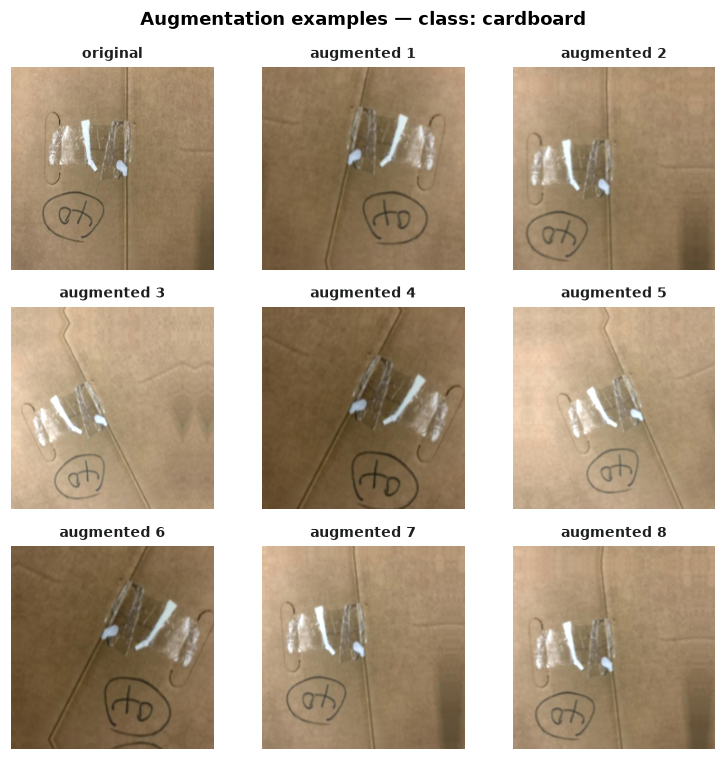

In [12]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomRotation(0.08, fill_mode="reflect", seed=SEED),
        layers.RandomZoom(0.15, fill_mode="reflect", seed=SEED),
        layers.RandomTranslation(0.10, 0.10, fill_mode="reflect", seed=SEED),
        layers.RandomContrast(0.20, seed=SEED),
        layers.RandomBrightness(0.15, value_range=(0, 255), seed=SEED),
    ],
    name="data_augmentation",
)


def make_dataset(df, shuffle):
    paths = df["path"].astype(str).to_numpy()
    labels = df["label_index"].astype("int32").to_numpy()
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(lambda path, label: (load_image(path), label), num_parallel_calls=AUTOTUNE).cache()
    if shuffle:
        dataset = dataset.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.batch(BATCH_SIZE).map(lambda images, labels: (tf.cast(images, tf.float32), labels))
    return dataset.prefetch(AUTOTUNE)


CUSTOM_OVERSAMPLE = 2  # custom industrial-metal photos are few; repeat them in the training set only
custom_rows = train_df[train_df["source"] == "custom"]
train_fit_df = pd.concat([train_df] + [custom_rows] * (CUSTOM_OVERSAMPLE - 1), ignore_index=True)
print(f"Training rows: {len(train_df)} + {len(custom_rows) * (CUSTOM_OVERSAMPLE - 1)} repeated custom rows")
train_ds = make_dataset(train_fit_df, shuffle=True)
val_ds = make_dataset(val_df, shuffle=False)
test_ds = make_dataset(test_df, shuffle=False)

for images, labels in train_ds.take(1):
    print(f"Training batch: images {tuple(images.shape)} {images.dtype.name}, labels {tuple(labels.shape)}")

example = tf.cast(load_image(train_df["path"][0]), tf.float32)[tf.newaxis]
fig, axes = plt.subplots(3, 3, figsize=(7, 7))
for i, ax in enumerate(axes.flat):
    shown = example[0] if i == 0 else data_augmentation(example, training=True)[0]
    ax.imshow(np.clip(keras.ops.convert_to_numpy(shown), 0, 255).astype("uint8"))
    ax.set_title("original" if i == 0 else f"augmented {i}", fontsize=9)
    ax.axis("off")
fig.suptitle(f"Augmentation examples — class: {train_df['label'][0]}", fontweight="bold")
plt.tight_layout()
plt.show()

## Section 8 — Handling class imbalance

When one class has far fewer images, the model can score well by mostly ignoring it.
**Class weights** make each mistake on a rare class count more in the loss.

The weights are computed by scikit-learn from the **training split only** using the `"balanced"` formula
`n_samples / (n_classes × n_samples_in_class)`. They are applied when the largest training class is more than
1.5× the smallest.

In [13]:
train_labels = train_df["label_index"].to_numpy()
weights = compute_class_weight(class_weight="balanced", classes=np.arange(NUM_CLASSES), y=train_labels)
train_counts = np.bincount(train_labels, minlength=NUM_CLASSES)
train_imbalance = train_counts.max() / train_counts.min()

USE_CLASS_WEIGHTS = bool(train_imbalance > 1.5)
CLASS_WEIGHTS = {int(i): float(w) for i, w in enumerate(weights)} if USE_CLASS_WEIGHTS else None

print(pd.DataFrame({"train_images": train_counts, "class_weight": weights.round(3)}, index=CLASS_NAMES).to_string())
print(f"\nTraining imbalance ratio: {train_imbalance:.2f}")
print("Class weights WILL be used." if USE_CLASS_WEIGHTS else "Classes are balanced enough; class weights will not be used.")

           train_images  class_weight
cardboard          1267         1.042
glass              1341         0.984
metal              1289         1.024
paper              1371         0.963
plastic            1629         0.810
trash              1022         1.291

Training imbalance ratio: 1.59
Class weights WILL be used.


## Section 9 — MobileNetV2 transfer learning

**Transfer learning** reuses a network that has already learned general visual features (edges, textures,
shapes) from the 1.2 million ImageNet images. We keep those features and only train a new classifier on top.

```
Input (224 × 224 × 3, RGB 0–255)
  ↓ Data augmentation (training only)
  ↓ Rescaling to [-1, 1]  (MobileNetV2 preprocessing, inside the model)
  ↓ MobileNetV2 base, ImageNet weights, frozen
  ↓ GlobalAveragePooling2D
  ↓ Dropout(0.2)
  ↓ Dense(256, ReLU, L2 regularisation)
  ↓ Dropout(0.4)
  ↓ Dense(6, softmax)  → probabilities for the six classes
```

Regularisation against over-fitting: dropout, L2 weight decay on the dense layer, data augmentation and early stopping.
The base model is called with `training=False` so its BatchNormalization layers always use their ImageNet statistics,
which is the recommended setting for fine-tuning later.

In [14]:
base_model = keras.applications.MobileNetV2(input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet")
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3), name="image")
x = data_augmentation(inputs)
x = mobilenet_preprocessing(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(0.2, name="dropout_features")(x)
x = layers.Dense(256, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4), name="dense_head")(x)
x = layers.Dropout(0.4, name="dropout_head")(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="probabilities")(x)
model = keras.Model(inputs, outputs, name="smart_waste_mobilenetv2")

model.summary(show_trainable=True)


def count_params(weights):
    return int(sum(np.prod(w.shape) for w in weights))


print(f"MobileNetV2 layers: {len(base_model.layers)}")
print(f"Trainable parameters    : {count_params(model.trainable_weights):,}")
print(f"Non-trainable parameters: {count_params(model.non_trainable_weights):,}")

Model: "smart_waste_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ image (InputLayer)          │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ data_augmentation           │ (None, 224, 224, 3)   │          0 │   -   │
│ (Sequential)                │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ mobilenetv2_preprocess      │ (None, 224, 224, 3)   │          0 │   -   │
│ (Rescaling)                 │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ mobilenetv2_1.00_224        │ (None, 7, 7, 1280)    │  2,257,984 │   N   │
│ (Functional)                │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling      │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout_features (Dropout)  │ (None, 1280)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense_head (Dense)          │ (None, 256)           │    327,936 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout_head (Dropout)      │ (None, 256)           │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ probabilities (Dense)       │ (None, 6)             │      1,542 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 2,587,462 (9.87 MB)

 Trainable params: 329,478 (1.26 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

MobileNetV2 layers: 154
Trainable parameters    : 329,478
Non-trainable parameters: 2,257,984


## Section 10 — Initial training (frozen base)

* **Optimizer:** Adam with learning rate `1e-3` — a standard choice for training a new head.
* **Loss:** sparse categorical cross-entropy (labels are integer class indices).
* **Metric:** accuracy.
* **Callbacks** (all monitor the **validation** loss, never the test set):
  * `EarlyStopping(patience=5, restore_best_weights=True)` — stops when validation loss stops improving.
  * `ReduceLROnPlateau(factor=0.3, patience=2)` — lowers the learning rate when progress stalls.
  * `ModelCheckpoint(save_best_only=True)` — keeps the best model on disk.

In [15]:
INITIAL_EPOCHS = 25
HEAD_CHECKPOINT = CHECKPOINT_DIR / "head_best.keras"
FINETUNE_CHECKPOINT = CHECKPOINT_DIR / "finetune_best.keras"
for checkpoint in (HEAD_CHECKPOINT, FINETUNE_CHECKPOINT):
    checkpoint.unlink(missing_ok=True)


def make_callbacks(checkpoint_path, initial_value_threshold=None):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7, verbose=1),
        keras.callbacks.ModelCheckpoint(
            checkpoint_path,
            monitor="val_loss",
            save_best_only=True,
            initial_value_threshold=initial_value_threshold,
            verbose=1,
        ),
    ]


model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=INITIAL_EPOCHS,
    class_weight=CLASS_WEIGHTS,
    verbose=2,
    callbacks=make_callbacks(HEAD_CHECKPOINT),
)
head_epochs_run = len(history_head.history["loss"])
best_head_val_loss = float(min(history_head.history["val_loss"]))
print(f"\nHead training ran for {head_epochs_run} epochs. Best validation loss: {best_head_val_loss:.4f}")

Epoch 1/25


C:\Users\User\computer_vision\.venv-training\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(



Epoch 1: val_loss improved from None to 0.62725, saving model to C:\Users\User\computer_vision\smart-waste\training\artifacts\checkpoints\head_best.keras



Epoch 1: finished saving model to C:\Users\User\computer_vision\smart-waste\training\artifacts\checkpoints\head_best.keras


250/250 - 189s - 758ms/step - accuracy: 0.6224 - loss: 1.0486 - val_accuracy: 0.7890 - val_loss: 0.6272 - learning_rate: 0.0010


...


Epoch 25: ReduceLROnPlateau reducing learning rate to 2.700000040931627e-05.



Epoch 25: val_loss did not improve from 0.43995


250/250 - 146s - 583ms/step - accuracy: 0.8951 - loss: 0.3584 - val_accuracy: 0.8627 - val_loss: 0.4427 - learning_rate: 9.0000e-05


Restoring model weights from the end of the best epoch: 23.



Head training ran for 25 epochs. Best validation loss: 0.4399


## Section 11 — Training visualisation

How to read the curves:

* **Training and validation both improving and close together** → healthy learning.
* **Training keeps improving while validation gets worse** → over-fitting (the model memorises the training images).
* **Both stay poor** → under-fitting (the model is too constrained or needs more training).

Validation accuracy can be *higher* than training accuracy here because dropout and augmentation are active
only during training, which makes the training task harder.

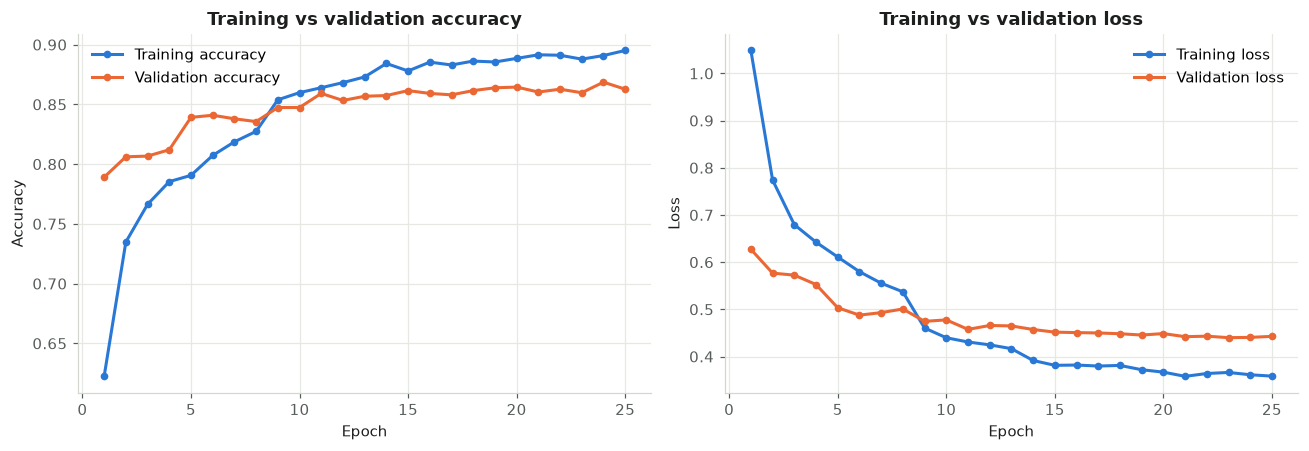

Last epoch — training accuracy: 0.8951, validation accuracy: 0.8627, gap: +0.0324


In [16]:
def plot_history(histories, fine_tune_start=None):
    merged = {key: sum((h.history[key] for h in histories), []) for key in ("accuracy", "val_accuracy", "loss", "val_loss")}
    epochs = np.arange(1, len(merged["loss"]) + 1)
    fig, (ax_acc, ax_loss) = plt.subplots(1, 2, figsize=(12, 4.2))
    panels = ((ax_acc, "accuracy", "Accuracy"), (ax_loss, "loss", "Loss"))
    for ax, key, title in panels:
        ax.plot(epochs, merged[key], color=COLORS["train"], linewidth=2, marker="o", markersize=4, label=f"Training {title.lower()}")
        ax.plot(epochs, merged[f"val_{key}"], color=COLORS["validation"], linewidth=2, marker="o", markersize=4, label=f"Validation {title.lower()}")
        if fine_tune_start is not None:
            ax.axvline(fine_tune_start + 0.5, color=INK_MUTED, linestyle="--", linewidth=1)
            ax.text(fine_tune_start + 0.7, ax.get_ylim()[1], "fine-tuning starts", va="top", fontsize=8, color=INK_MUTED)
        ax.set_title(f"Training vs validation {title.lower()}")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(title)
        ax.legend()
    plt.tight_layout()
    return fig


plot_history([history_head])
plt.show()

final_train_acc = history_head.history["accuracy"][-1]
final_val_acc = history_head.history["val_accuracy"][-1]
print(f"Last epoch — training accuracy: {final_train_acc:.4f}, validation accuracy: {final_val_acc:.4f}, "
      f"gap: {final_train_acc - final_val_acc:+.4f}")

## Section 12 — Fine-tuning

The frozen base already gives good features, but they were learned for ImageNet objects. Fine-tuning lets the
**deepest** MobileNetV2 layers adapt to waste materials.

* **Only the last blocks are unfrozen** (from `block_10_expand` to the end — roughly the top third of the
  network). Early layers detect generic edges and textures that are useful as they are; the deep layers
  encode more task-specific patterns. Unfreezing everything on a few thousand images would risk destroying
  the pretrained features and over-fitting.
* **BatchNormalization layers stay frozen**, so their ImageNet statistics are not disturbed by small batches.
* **Learning rate 3e-5** (about 30× smaller) makes small, careful updates to the pretrained weights.
* The fine-tuning checkpoint is only saved if it **beats the best validation loss from Section 10**; otherwise
  the head-only model is kept. This decision uses validation data only.

In [17]:
FINE_TUNE_FROM_LAYER = "block_10_expand"
FINE_TUNE_EPOCHS = 40
FINE_TUNE_LEARNING_RATE = 3e-5

base_model.trainable = True
layer_names = [layer.name for layer in base_model.layers]
fine_tune_at = layer_names.index(FINE_TUNE_FROM_LAYER)
for index, layer in enumerate(base_model.layers):
    layer.trainable = index >= fine_tune_at and not isinstance(layer, layers.BatchNormalization)

unfrozen = [layer.name for layer in base_model.layers if layer.trainable]
print(f"Unfreezing MobileNetV2 from layer {fine_tune_at} ('{FINE_TUNE_FROM_LAYER}') of {len(base_model.layers)}")
print(f"Trainable MobileNetV2 layers: {len(unfrozen)} (BatchNormalization layers kept frozen)")
print(f"Trainable parameters now: {count_params(model.trainable_weights):,}")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=FINE_TUNE_LEARNING_RATE),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=head_epochs_run + FINE_TUNE_EPOCHS,
    initial_epoch=head_epochs_run,
    class_weight=CLASS_WEIGHTS,
    verbose=2,
    callbacks=make_callbacks(FINETUNE_CHECKPOINT, initial_value_threshold=best_head_val_loss),
)
fine_epochs_run = len(history_fine.history["loss"])

Unfreezing MobileNetV2 from layer 90 ('block_10_expand') of 154
Trainable MobileNetV2 layers: 42 (BatchNormalization layers kept frozen)
Trainable parameters now: 2,289,286
Epoch 26/65



Epoch 26: val_loss did not improve from 0.43995


250/250 - 182s - 728ms/step - accuracy: 0.8613 - loss: 0.4379 - val_accuracy: 0.8633 - val_loss: 0.4526 - learning_rate: 3.0000e-05


Epoch 27/65



Epoch 27: val_loss improved from 0.43995 to 0.43736, saving model to C:\Users\User\computer_vision\smart-waste\training\artifacts\checkpoints\finetune_best.keras


...

Epoch 37/65



Epoch 37: val_loss did not improve from 0.39090


250/250 - 173s - 692ms/step - accuracy: 0.9636 - loss: 0.1635 - val_accuracy: 0.8969 - val_loss: 0.3967 - learning_rate: 8.1000e-07


Epoch 37: early stopping


Restoring model weights from the end of the best epoch: 30.


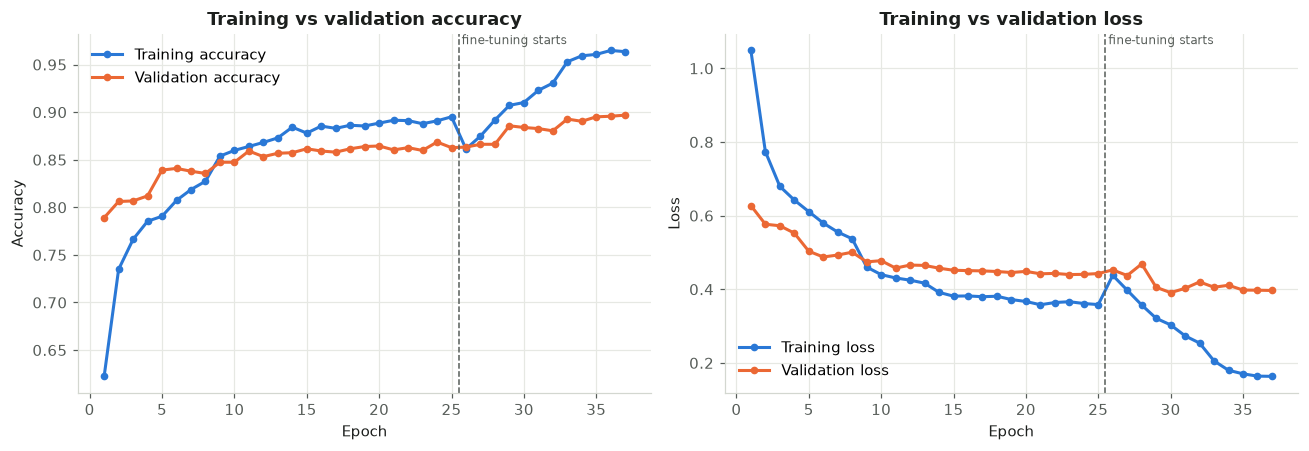

Selected model: fine-tuned
Validation loss 0.3909, validation accuracy 0.8839


In [18]:
fig = plot_history([history_head, history_fine], fine_tune_start=head_epochs_run)
fig.savefig(ARTIFACTS_DIR / "training_curves.png", bbox_inches="tight")
plt.show()

if FINETUNE_CHECKPOINT.exists():
    selected_checkpoint, selected_stage = FINETUNE_CHECKPOINT, "fine-tuned"
else:
    selected_checkpoint, selected_stage = HEAD_CHECKPOINT, "head-only (fine-tuning did not improve validation loss)"
final_model = keras.models.load_model(selected_checkpoint)

best_val_loss, best_val_accuracy = final_model.evaluate(val_ds, verbose=0)
print(f"Selected model: {selected_stage}")
print(f"Validation loss {best_val_loss:.4f}, validation accuracy {best_val_accuracy:.4f}")

pd.DataFrame({key: history_head.history[key] + history_fine.history[key] for key in ("accuracy", "val_accuracy", "loss", "val_loss")}).to_csv(
    ARTIFACTS_DIR / "training_history.csv", index_label="epoch_index"
)

## Section 13 — Final evaluation on the untouched test set

This is the **first and only time** the test set is used. Nothing was tuned on it, so these numbers are an honest
estimate of performance on new images *from the same distributions as TrashNet and RealWaste*. Results are
reported for the whole test set and separately for each source.

* **Precision** — of the images predicted as a class, how many really are that class.
* **Recall** — of the images that really are a class, how many the model found.
* **F1-score** — the harmonic mean of precision and recall.
* **Macro average** treats every class equally (important for the small *trash* class);
  **weighted average** weights classes by their number of test images.

In [19]:
test_loss, test_accuracy = final_model.evaluate(test_ds, verbose=0)
y_prob = final_model.predict(test_ds, verbose=0)
y_pred = y_prob.argmax(axis=1)
y_true = test_df["label_index"].to_numpy()

macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
weighted_p, weighted_r, weighted_f1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
assert abs(accuracy_score(y_true, y_pred) - test_accuracy) < 1e-6

metrics = {
    "test_samples": int(len(y_true)),
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "macro_precision": float(macro_p),
    "macro_recall": float(macro_r),
    "macro_f1": float(macro_f1),
    "weighted_precision": float(weighted_p),
    "weighted_recall": float(weighted_r),
    "weighted_f1": float(weighted_f1),
}
print(f"Test images      : {metrics['test_samples']}")
print(f"Test loss        : {test_loss:.4f}")
print(f"Test accuracy    : {test_accuracy:.4f}")
print(f"Macro precision  : {macro_p:.4f}")
print(f"Macro recall     : {macro_r:.4f}")
print(f"Macro F1-score   : {macro_f1:.4f}")
print(f"Weighted F1-score: {weighted_f1:.4f}\n")

report_text = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0)
print(report_text)
(ARTIFACTS_DIR / "classification_report.txt").write_text(report_text)

source_rows = []
for source in SOURCES:
    mask = test_df["source"].to_numpy() == source
    source_p, source_r, source_f1, _ = precision_recall_fscore_support(y_true[mask], y_pred[mask], average="macro", zero_division=0)
    source_rows.append({
        "source": source,
        "test_images": int(mask.sum()),
        "accuracy": float(accuracy_score(y_true[mask], y_pred[mask])),
        "macro_precision": float(source_p),
        "macro_recall": float(source_r),
        "macro_f1": float(source_f1),
    })
by_source = pd.DataFrame(source_rows).set_index("source")
print("Performance per source:")
print(by_source.round(4).to_string())
metrics["by_source"] = by_source.to_dict(orient="index")
(ARTIFACTS_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2))

Test images      : 1698
Test loss        : 0.4287
Test accuracy    : 0.8751
Macro precision  : 0.8774
Macro recall     : 0.8743
Macro F1-score   : 0.8757
Weighted F1-score: 0.8752

              precision    recall  f1-score   support

   cardboard     0.9007    0.9007    0.9007       272
       glass     0.8763    0.8641    0.8702       287
       metal     0.8839    0.8520    0.8676       277
       paper     0.8973    0.8912    0.8942       294
     plastic     0.8320    0.8797    0.8552       349
       trash     0.8744    0.8584    0.8664       219

    accuracy                         0.8751      1698
   macro avg     0.8774    0.8743    0.8757      1698
weighted avg     0.8757    0.8751    0.8752      1698

Performance per source:
           test_images  accuracy  macro_precision  macro_recall  macro_f1
source                                                                   
trashnet           378    0.8386           0.8097        0.7873    0.7917
realwaste          538    0.81

1174

## Section 14 — Confusion matrix

Rows are the **true** classes and columns the **predicted** classes. The diagonal holds correct predictions.
The right-hand matrix is normalised per row, so each row shows how a true class was distributed across predictions
(the diagonal equals per-class recall).

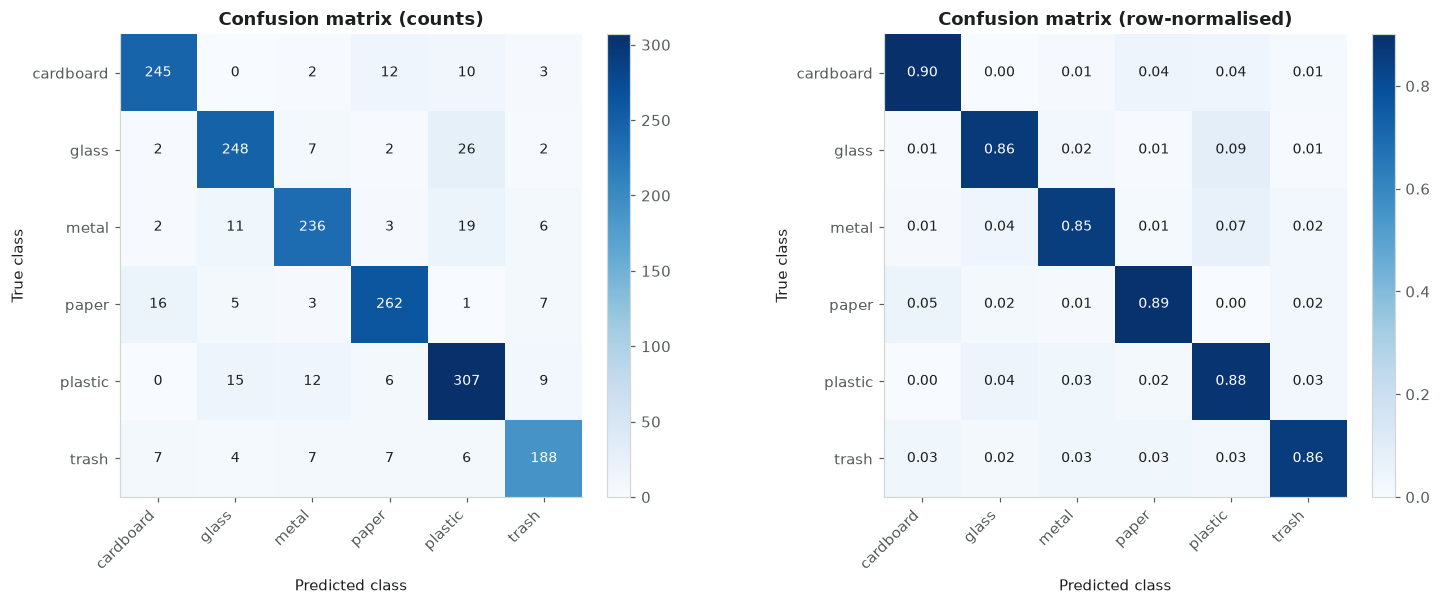

Most common confusions:
     true predicted_as  count  share_of_true_class
    glass      plastic     26               0.0906
    metal      plastic     19               0.0686
    paper    cardboard     16               0.0544
  plastic        glass     15               0.0430
  plastic        metal     12               0.0344
cardboard        paper     12               0.0441
    metal        glass     11               0.0397
cardboard      plastic     10               0.0368


In [20]:
cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
cm_normalised = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
for ax, matrix, title, fmt in ((axes[0], cm, "Confusion matrix (counts)", "d"), (axes[1], cm_normalised, "Confusion matrix (row-normalised)", ".2f")):
    image = ax.imshow(matrix, cmap="Blues", vmin=0)
    ax.set_xticks(np.arange(NUM_CLASSES), labels=CLASS_NAMES, rotation=45, ha="right")
    ax.set_yticks(np.arange(NUM_CLASSES), labels=CLASS_NAMES)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_title(title)
    ax.grid(False)
    threshold = matrix.max() / 2
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, format(matrix[i, j], fmt), ha="center", va="center", fontsize=9,
                    color="white" if matrix[i, j] > threshold else INK)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
fig.savefig(ARTIFACTS_DIR / "confusion_matrix.png", bbox_inches="tight")
plt.show()

confusions = [
    {"true": CLASS_NAMES[i], "predicted_as": CLASS_NAMES[j], "count": int(cm[i, j]), "share_of_true_class": round(cm_normalised[i, j], 4)}
    for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0
]
confusions_df = pd.DataFrame(confusions)
if confusions_df.empty:
    print("No misclassifications on the test set.")
else:
    print("Most common confusions:")
    print(confusions_df.sort_values("count", ascending=False).head(8).to_string(index=False))

## Section 15 — Per-class performance

The table and chart show precision, recall and F1-score for every class, sorted from weakest to strongest F1.
Classes with an F1-score below 0.80 are flagged as needing improvement — they are reported, not hidden.

           precision  recall  f1_score  support
plastic       0.8320  0.8797    0.8552      349
trash         0.8744  0.8584    0.8664      219
metal         0.8839  0.8520    0.8676      277
glass         0.8763  0.8641    0.8702      287
paper         0.8973  0.8912    0.8942      294
cardboard     0.9007  0.9007    0.9007      272

Strongest class: cardboard (F1 0.9007)
Weakest class  : plastic (F1 0.8552)
All classes reach an F1-score of at least 0.80.


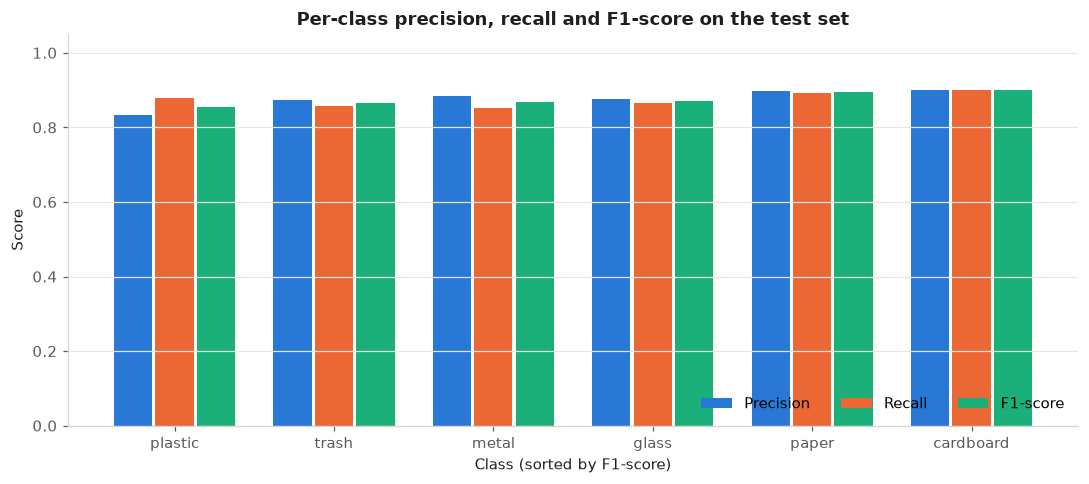

In [21]:
p, r, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=np.arange(NUM_CLASSES), zero_division=0)
per_class = pd.DataFrame({"precision": p, "recall": r, "f1_score": f1, "support": support}, index=CLASS_NAMES).sort_values("f1_score")
print(per_class.round(4).to_string())
per_class.to_csv(ARTIFACTS_DIR / "per_class_metrics.csv")

strongest, weakest = per_class.index[-1], per_class.index[0]
print(f"\nStrongest class: {strongest} (F1 {per_class.loc[strongest, 'f1_score']:.4f})")
print(f"Weakest class  : {weakest} (F1 {per_class.loc[weakest, 'f1_score']:.4f})")
needs_work = per_class[per_class["f1_score"] < 0.80]
if needs_work.empty:
    print("All classes reach an F1-score of at least 0.80.")
else:
    print(f"Classes below F1 0.80 (need improvement): {', '.join(needs_work.index)}")

fig, ax = plt.subplots(figsize=(10, 4.5))
positions = np.arange(len(per_class))
width = 0.26
for offset, column, color, label in ((-width, "precision", COLORS["train"], "Precision"), (0, "recall", COLORS["validation"], "Recall"), (width, "f1_score", COLORS["third"], "F1-score")):
    ax.bar(positions + offset, per_class[column], width=width - 0.02, color=color, label=label)
ax.set_xticks(positions, labels=per_class.index)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_xlabel("Class (sorted by F1-score)")
ax.set_title("Per-class precision, recall and F1-score on the test set")
ax.grid(axis="x", visible=False)
ax.legend(ncol=3, loc="lower right")
plt.tight_layout()
plt.show()

## Section 16 — Individual image testing

`predict_image(image_path, actual_label=None)` loads an image with the **same `load_image()` function** used for
training, runs the final model, and shows the image, the predicted class, the confidence and the probability of
every class. All values come directly from the model's softmax output.

To try your own photo in Colab, set `UPLOAD_OWN_IMAGE = True` and choose an image file from your computer.

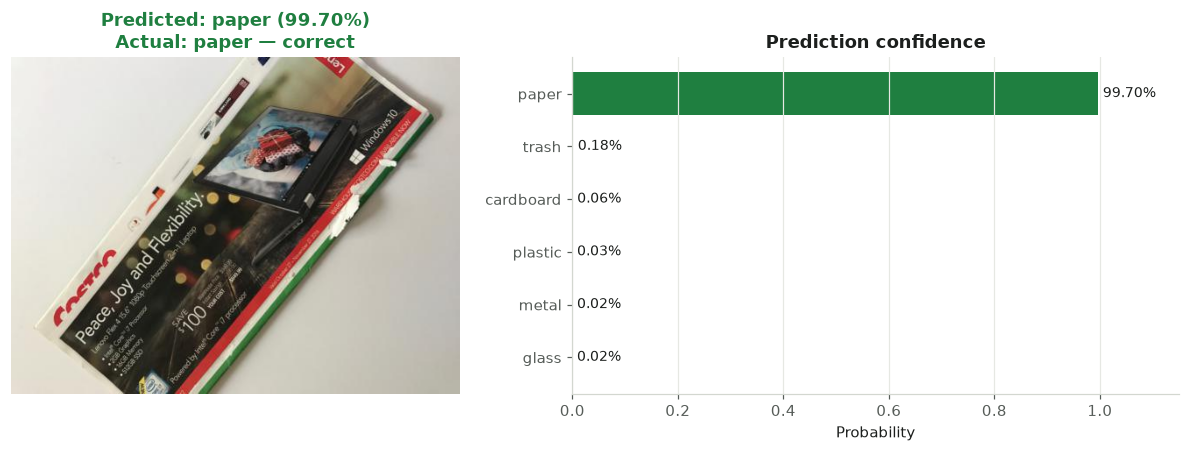

Prediction: Paper
Confidence: 99.70%

Cardboard  0.06%
Glass      0.02%
Metal      0.02%
Paper      99.70%
Plastic    0.03%
Trash      0.18%


In [22]:
def predict_image(image_path, actual_label=None, model_to_use=None):
    model_to_use = model_to_use or final_model
    image = load_image(str(image_path))
    probabilities = model_to_use.predict(tf.cast(image, tf.float32)[tf.newaxis], verbose=0)[0]
    order = np.argsort(probabilities)[::-1]
    predicted = CLASS_NAMES[order[0]]
    confidence = float(probabilities[order[0]])

    fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.3]})
    with Image.open(image_path) as original:
        ax_img.imshow(original.convert("RGB"))
    ax_img.axis("off")
    title = f"Predicted: {predicted} ({confidence:.2%})"
    if actual_label is not None:
        correct = actual_label == predicted
        title += f"\nActual: {actual_label} — {'correct' if correct else 'incorrect'}"
        ax_img.set_title(title, color=COLORS["correct"] if correct else COLORS["wrong"])
    else:
        ax_img.set_title(title)

    names = [CLASS_NAMES[i] for i in order][::-1]
    values = probabilities[order][::-1]
    bar_colors = [COLORS["brand"] if name == predicted else "#b9bdb7" for name in names]
    bars = ax_bar.barh(names, values, color=bar_colors)
    ax_bar.bar_label(bars, labels=[f"{v:.2%}" for v in values], padding=3, fontsize=9, color=INK)
    ax_bar.set_xlim(0, 1.15)
    ax_bar.set_xlabel("Probability")
    ax_bar.set_title("Prediction confidence")
    ax_bar.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()

    print(f"Prediction: {predicted.capitalize()}")
    print(f"Confidence: {confidence:.2%}\n")
    for index, name in enumerate(CLASS_NAMES):
        print(f"{name.capitalize():<10} {probabilities[index]:.2%}")
    return {"predicted": predicted, "confidence": confidence, "probabilities": dict(zip(CLASS_NAMES, map(float, probabilities)))}


example_row = test_df.sample(1, random_state=SEED).iloc[0]
_ = predict_image(example_row["path"], actual_label=example_row["label"])

In [23]:
UPLOAD_OWN_IMAGE = False

if UPLOAD_OWN_IMAGE:
    if IN_COLAB:
        from google.colab import files

        uploaded = files.upload()
        for file_name in uploaded:
            predict_image(WORK_DIR / file_name)
    else:
        print("Outside Colab, call predict_image('path/to/image.jpg') directly.")

## Section 17 — Random test samples

Twelve random images from the untouched test set with their actual class, predicted class and confidence.
Green titles are correct predictions, red titles are mistakes.

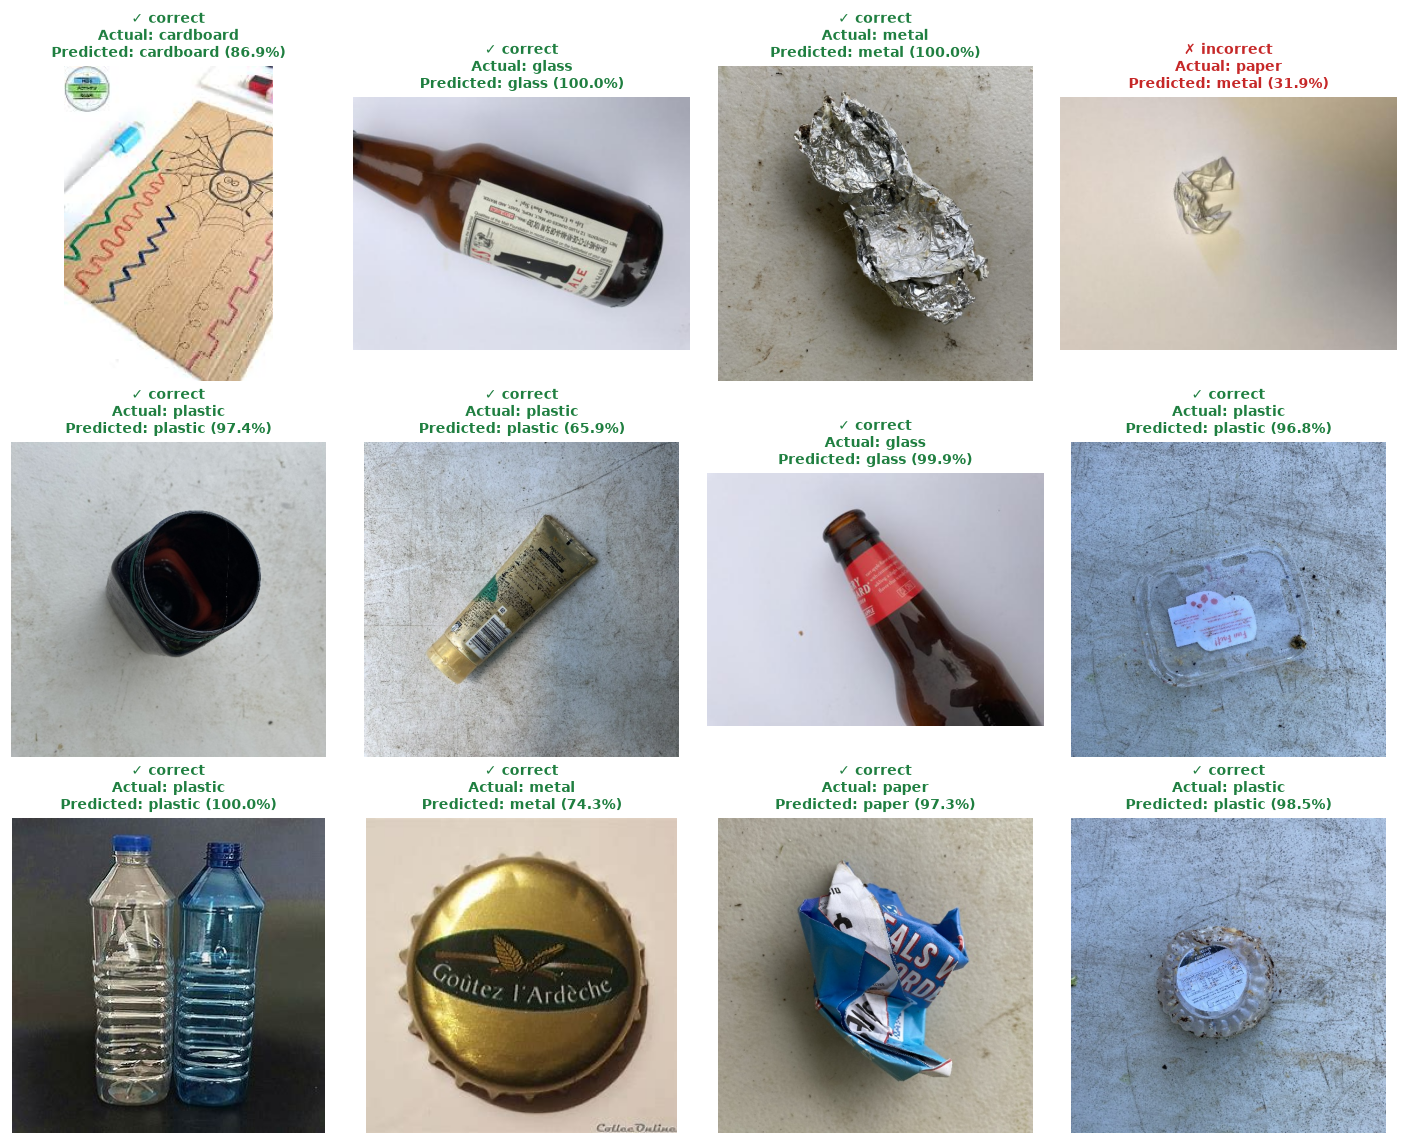

Correct in this sample: 11 / 12


In [24]:
sample_indices = np.random.default_rng(SEED).choice(len(test_df), size=min(12, len(test_df)), replace=False)
fig, axes = plt.subplots(3, 4, figsize=(13, 10.5))
for ax, index in zip(axes.flat, sample_indices):
    row = test_df.iloc[index]
    predicted = CLASS_NAMES[y_pred[index]]
    confidence = y_prob[index, y_pred[index]]
    correct = predicted == row["label"]
    with Image.open(row["path"]) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(
        f"{'✓ correct' if correct else '✗ incorrect'}\nActual: {row['label']}\nPredicted: {predicted} ({confidence:.1%})",
        fontsize=9,
        color=COLORS["correct"] if correct else COLORS["wrong"],
    )
    ax.axis("off")
for ax in list(axes.flat)[len(sample_indices):]:
    ax.axis("off")
plt.tight_layout()
plt.show()
print(f"Correct in this sample: {sum(CLASS_NAMES[y_pred[i]] == test_df.iloc[i]['label'] for i in sample_indices)} / {len(sample_indices)}")

## Section 18 — Save the model

The final model is saved in the native Keras format. Reloading it and comparing predictions confirms the file is complete.
The class order, input size and preprocessing are written to `metadata.json` in Section 21.

In [25]:
MODEL_VERSION = "1.3.1"
FINAL_MODEL_PATH = ARTIFACTS_DIR / "smart_waste_mobilenetv2.keras"
final_model.save(FINAL_MODEL_PATH)

reloaded = keras.models.load_model(FINAL_MODEL_PATH)
check_batch = next(iter(test_ds))[0]
max_difference = float(np.abs(reloaded.predict(check_batch, verbose=0) - final_model.predict(check_batch, verbose=0)).max())
assert max_difference < 1e-5, max_difference
print(f"Saved {FINAL_MODEL_PATH} ({FINAL_MODEL_PATH.stat().st_size / 1e6:.1f} MB); reload check passed (max diff {max_difference:.2e}).")

Saved C:\Users\User\computer_vision\smart-waste\training\artifacts\smart_waste_mobilenetv2.keras (29.3 MB); reload check passed (max diff 0.00e+00).


## Section 19 — Choosing the web runtime: ONNX Runtime Web

The website runs the model **in the visitor's browser**, so Vercel only serves static files and no Python server is needed.
Two runtimes were considered:

| | TensorFlow.js | **ONNX Runtime Web (chosen)** |
|---|---|---|
| Converter | `tensorflowjs` pip package, whose pinned dependencies frequently conflict with Colab's TensorFlow/Keras 3 | `tf2onnx`, converting a traced TensorFlow function — works with Keras 3 models |
| Verification | Requires running JavaScript | `onnxruntime` for Python executes the **same ONNX file** with the same operators, so we can compare it with Keras right here |
| Browser package | Larger JS library with many unused ops | Small JS API + one WebAssembly binary, served from the app itself |

The model is traced with `training=False`, so the augmentation layers are inactive and only the inference path is exported.

In [26]:
%pip install -q onnx onnxruntime
%pip install -q --no-deps tf2onnx

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\User\computer_vision\.venv-training\Scripts\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\User\computer_vision\.venv-training\Scripts\python.exe -m pip install --upgrade pip


In [27]:
import onnx
import onnxruntime
import tf2onnx

ONNX_MODEL_FILE = "smart_waste_mobilenetv2.onnx"
ONNX_MODEL_PATH = WEB_MODEL_DIR / ONNX_MODEL_FILE
ONNX_INPUT_NAME = "image"

input_signature = [tf.TensorSpec((None, *IMG_SIZE, 3), tf.float32, name=ONNX_INPUT_NAME)]


@tf.function(input_signature=input_signature)
def serving_function(image):
    return {"probabilities": final_model(image, training=False)}


onnx_model, _ = tf2onnx.convert.from_function(
    serving_function, input_signature=input_signature, opset=17, output_path=str(ONNX_MODEL_PATH)
)
onnx.checker.check_model(onnx_model)

graph_inputs = [graph_input.name for graph_input in onnx_model.graph.input]
graph_outputs = [graph_output.name for graph_output in onnx_model.graph.output]
assert len(graph_inputs) == 1 and len(graph_outputs) == 1, (graph_inputs, graph_outputs)
ONNX_OUTPUT_NAME = graph_outputs[0]
assert graph_inputs[0] == ONNX_INPUT_NAME, graph_inputs

session = onnxruntime.InferenceSession(str(ONNX_MODEL_PATH), providers=["CPUExecutionProvider"])
session_input = session.get_inputs()[0]
session_output = session.get_outputs()[0]
print(f"ONNX model written: {ONNX_MODEL_PATH} ({ONNX_MODEL_PATH.stat().st_size / 1e6:.1f} MB)")
print(f"Input : name='{session_input.name}', shape={session_input.shape}, type={session_input.type}")
print(f"Output: name='{session_output.name}', shape={session_output.shape}, type={session_output.type}")
assert session_input.shape[1:] == [IMG_SIZE[0], IMG_SIZE[1], 3]
assert session_output.shape[-1] == NUM_CLASSES

ONNX model written: C:\Users\User\computer_vision\smart-waste\training\artifacts\web_model\smart_waste_mobilenetv2.onnx (10.2 MB)
Input : name='image', shape=['unk__655', 224, 224, 3], type=tensor(float)
Output: name='probabilities', shape=['unk__656', 6], type=tensor(float)


## Section 20 — Verify the ONNX model against the Keras model

The whole test set is run through both models with **identical input tensors**. The predicted classes must agree and the
probabilities must match to within floating-point tolerance. This confirms the input shape (NHWC), RGB order,
embedded normalisation, softmax output and class order survived the conversion.

In [28]:
onnx_probabilities = np.concatenate([
    session.run([ONNX_OUTPUT_NAME], {ONNX_INPUT_NAME: images.numpy()})[0] for images, _ in test_ds
])
max_abs_difference = float(np.abs(onnx_probabilities - y_prob).max())
argmax_agreement = float((onnx_probabilities.argmax(axis=1) == y_pred).mean())
row_sums = onnx_probabilities.sum(axis=1)

print(f"Images compared            : {len(onnx_probabilities)}")
print(f"Max |ONNX − Keras|         : {max_abs_difference:.2e}")
print(f"Predicted class agreement  : {argmax_agreement:.2%}")
print(f"Softmax row sums           : min {row_sums.min():.6f}, max {row_sums.max():.6f}")

assert max_abs_difference < 1e-3, "ONNX probabilities differ from Keras — do not deploy this model."
assert np.allclose(row_sums, 1.0, atol=1e-4)
onnx_parity = {
    "images_compared": int(len(onnx_probabilities)),
    "max_abs_difference": max_abs_difference,
    "argmax_agreement": argmax_agreement,
}

Images compared            : 1698
Max |ONNX − Keras|         : 1.00e-05
Predicted class agreement  : 100.00%
Softmax row sums           : min 1.000000, max 1.000000


## Section 21 — Write `metadata.json` and download the web model

`metadata.json` is the contract between this notebook and the website. The web app reads it at runtime and refuses to
classify if anything is inconsistent. It records:

* the **class-index mapping** in the exact order the model outputs it,
* the ONNX input/output names, input size, NHWC layout, RGB order and the [0, 255] pixel range,
* that MobileNetV2 preprocessing is embedded in the model,
* the real test metrics from Section 13 (displayed on the website's *About* section),
* the split sizes, seed and ONNX parity check.

Download `smart_waste_web_model.zip`, extract it, and copy **both files** into `smart-waste/public/model/`.

In [29]:
metadata = {
    "format_version": 1,
    "model_name": "smart_waste_mobilenetv2",
    "model_version": MODEL_VERSION,
    "created_at": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
    "architecture": "MobileNetV2 (ImageNet) + GlobalAveragePooling + Dropout + Dense(256) + Dropout + Dense(6, softmax)",
    "model_file": ONNX_MODEL_FILE,
    "input": {
        "name": ONNX_INPUT_NAME,
        "height": IMG_SIZE[0],
        "width": IMG_SIZE[1],
        "channels": 3,
        "layout": "NHWC",
        "color_order": "RGB",
        "dtype": "float32",
        "pixel_range": [0, 255],
        "resize": "bilinear with antialiasing, aspect ratio not preserved",
    },
    "preprocessing": {
        "embedded_in_model": True,
        "operation": "x / 127.5 - 1 (keras.applications.mobilenet_v2.preprocess_input)",
    },
    "output": {"name": ONNX_OUTPUT_NAME, "activation": "softmax", "num_classes": NUM_CLASSES},
    "class_names": CLASS_NAMES,
    "class_index": {str(index): name for index, name in enumerate(CLASS_NAMES)},
    "dataset": {
        "name": "TrashNet + RealWaste + Garbage Dataset + Custom photos",
        "sources": {
            "trashnet": "https://github.com/garythung/trashnet",
            "realwaste": "https://archive.ics.uci.edu/dataset/908/realwaste (CC BY 4.0)",
            "garbage": "https://huggingface.co/datasets/steveharianto/waste-garbage-management-dataset (MIT)",
            "custom": "custom_real/<class>/ (101 curated photos (Wikimedia Commons and own collection): 47 metal stock, 26 trash bags, 28 glass)",
        },
        "seed": SEED,
        "split": {"train": len(train_df), "validation": len(val_df), "test": len(test_df)},
    },
    "training": {
        "head_epochs": head_epochs_run,
        "fine_tune_epochs": fine_epochs_run,
        "fine_tune_from_layer": FINE_TUNE_FROM_LAYER,
        "selected_checkpoint": selected_stage,
        "class_weights_used": USE_CLASS_WEIGHTS,
    },
    "metrics": metrics,
    "onnx_parity": onnx_parity,
}

metadata_path = WEB_MODEL_DIR / "metadata.json"
metadata_path.write_text(json.dumps(metadata, indent=2))
print(metadata_path.read_text())

web_zip = shutil.make_archive(str(ARTIFACTS_DIR / "smart_waste_web_model"), "zip", WEB_MODEL_DIR)
print(f"\nWeb model package: {web_zip}")
print("Copy smart_waste_mobilenetv2.onnx and metadata.json into smart-waste/public/model/")

if IN_COLAB:
    from google.colab import files

    files.download(web_zip)
    files.download(str(FINAL_MODEL_PATH))

{
  "format_version": 1,
  "model_name": "smart_waste_mobilenetv2",
  "model_version": "1.3.1",
  "created_at": "2026-10-22T16:58:20+00:00",
  "architecture": "MobileNetV2 (ImageNet) + GlobalAveragePooling + Dropout + Dense(256) + Dropout + Dense(6, softmax)",
  "model_file": "smart_waste_mobilenetv2.onnx",
  "input": {
    "name": "image",
    "height": 224,
    "width": 224,
    "channels": 3,
    "layout": "NHWC",
    "color_order": "RGB",
    "dtype": "float32",
    "pixel_range": [
      0,
      255
    ],
    "resize": "bilinear with antialiasing, aspect ratio not preserved"
  },
  "preprocessing": {
    "embedded_in_model": true,
    "operation": "x / 127.5 - 1 (keras.applications.mobilenet_v2.preprocess_input)"
  },
  "output": {
    "name": "probabilities",
    "activation": "softmax",
    "num_classes": 6
  },
  "class_names": [
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic",
    "trash"
  ],
  "class_index": {
    "0": "cardboard",
    "1": "glass",
 


Web model package: C:\Users\User\computer_vision\smart-waste\training\artifacts\smart_waste_web_model.zip
Copy smart_waste_mobilenetv2.onnx and metadata.json into smart-waste/public/model/


## Next steps

1. Extract `smart_waste_web_model.zip` and copy `smart_waste_mobilenetv2.onnx` and `metadata.json` into
   `smart-waste/public/model/`.
2. In `smart-waste/`, run `npm install` and `npm run dev`, then open <http://localhost:3000> and classify a few images.
3. Copy the real metrics printed in Section 13 (also saved to `artifacts/metrics.json`) and the confusion matrix
   image into the README's *Model Evaluation* section.
4. Commit, push to GitHub and import the repository into Vercel (see the README).

Colab storage is temporary: download `artifacts/` (or copy it to Google Drive) before closing the session.